# Where temperature changes the algorithm an LLM writes — demo

*Iteration 7, claim T (round 7, experiment 35). Model: **Qwen3-8B** (revision `b968826d`, bf16, thinking off), writing
Python for coding tasks.*

**The question.** Is temperature the LLM's "creativity knob"? On three coding units the model writes one of two known
algorithms:

- **B3** (minimum spanning tree weight): Kruskal 0.80 vs Prim with a heap 0.19;
- **A3** (trapped rain water): prefix/suffix maximum arrays 0.68 vs two pointers 0.31;
- **B6** (valid anagram): sort and compare 0.77 vs a fixed 26-slot count array 0.13.

On four other tasks it writes only one algorithm: T1 grid path (BFS), T2 shortest path (Dijkstra), T10 connected
components (union-find) and T03 k-th smallest (full sort).

**What the experiment does.**

1. **Where is the algorithm decided? (Test 1)** Prefix resampling: force the first *k* tokens of a sampled program,
   resample the rest, and find the token where the algorithm becomes fixed (Bayesian change points, then a
   20-continuation confirmation).
2. **Can temperature's effect be predicted in advance? (Test 2)** A prediction function reads the teacher-forced logits
   along the opening and at that fork, together with the token conditionals P(A | fork token). It predicts each
   algorithm's share at T = 0.3 / 0.7 / 1.0 / 1.3 with top-p 1 or top-k 10. The predictions were hash-committed before
   any temperature sample and are scored against a same-seed sweep: the same 50 uniform streams in all 8 cells.
3. **Collapsed tasks (Test 3).** Is the alternative ≥ 4 nats behind at the fork, out of temperature's reach?
4. **Is the fork linked to the task-state plan? (S4)** Push the task-specification states in random directions (S4(a)).
   Or exchange in the states of a prompt that names the minority algorithm (S4(b)).

**Committed result: PARTIAL.**

- Test 1 passes on 3/3 units. The algorithm is decided by one sampled token right after the canonical opening, e.g.
  ` Kr` vs ` Prim` after `    # `.
- Test 2 fails: it passes on B3 only.
- Test 3 passes on 4/4 tasks.
- The S4(b) exchange gives the minority algorithm on 30/30 seeds on every unit.
- Temperature only reweights the 2–3 known ideas. Their phrasings multiply, but none of the 2,290 programs is a novel
  algorithm.

**What this notebook runs.** `method.py` is a stage orchestrator. Its GPU stages need Qwen3-8B on a ≥ 20 GB GPU (about
0.75 GPU-hours in the committed run). The notebook keeps the orchestrator verbatim, so it prints the stage plan. It then
runs the CPU side of the method inline on the stored outputs of the GPU stages (`mini_demo_data.json`):

| Section | Original code | What runs here |
|---|---|---|
| 3 | `src/replay.py`, `src/predict.py` | the sampler, the committed prediction function and its unit tests U5, U8 |
| 4 | `src/forks.py`, `src/stages7.py` (CPU part), `src/cpu7.py` (U4) | the whole fork-scan analysis, from the 8,376 stored continuations |
| 5 | `src/predictions7.py`, `src/commit7.py` | the Test-1 numbers; the prediction function on the surviving real teacher-forced logits (S4(b) arms of A3 and B6); the commit chain U7 |
| 6 | `src/analysis_T.py` | the committed scoring: Tests 1–3, verdict, S4(a), S4(b), the ideas-vs-phrasings table |
| 7 | `src/figures7.py` | figures F1–F7, including F7: the fork-token states in activation space |
| 8 | notebook | every recomputed number next to the committed one, and a summary figure |

Every change to the original code is marked `# notebook:`.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install (method.py and src/cfg7.py log with it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib -- pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- method.py
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# --- src/cfg7.py, src/forks.py, src/predictions7.py, src/stages7.py, src/analysis_T.py, src/commit7.py, src/cpu7.py
import ast
import hashlib
import itertools
import json
import math
import os
import random
import resource
from collections import Counter, defaultdict
from datetime import datetime, timezone
from typing import Any, Iterable

import numpy as np
from scipy.special import gammaln, logsumexp
from scipy.stats import binom, fisher_exact, spearmanr

# --- src/figures7.py (notebook: inline backend, so no matplotlib.use("Agg"))
import matplotlib
import matplotlib.pyplot as plt

# --- notebook additions: base64-stored arrays, module namespaces, inline display
import base64
import types
from IPython.display import display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-7/experiment-35/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta = data["metadata"]
print(meta["title"])
print(f"model: {meta['model']}; committed verdict: {meta['verdict']}")
print(f"{meta['n_examples']} sweep seed positions holding {meta['n_sweep_programs']} programs; "
      f"{meta['n_twin_rows']} twin, {meta['n_s4_rows']} S4 and {meta['n_collapsed_rows']} collapsed-check programs; "
      f"{meta['n_continuations']} fork-scan continuations; S4(b) teacher-forced logits for {meta['tf_s4_units']}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Where temperature changes the algorithm an LLM writes (iteration 7, claim T)
model: Qwen/Qwen3-8B@b968826d (bf16, thinking off); committed verdict: PARTIAL
50 sweep seed positions holding 1200 programs; 300 twin, 630 S4 and 80 collapsed-check programs; 8376 fork-scan continuations; S4(b) teacher-forced logits for ['A3', 'B6']


## Configuration

The data are the full committed data at every setting. The parameters below only set how many random replicates or
permutations a statistic uses. The comments give the committed run's values.

- `N_BOOT_H`: bootstrap replicates of H(A | fork class), Test 1.
- `N_BOOT_DELTA`: slot-bootstrap replicates of the T 1.0 → 0.3 drop, Test 2.
- `N_PERM_FORK`: label permutations of the fork scan's sensitivity statistic.
- `N_U4_RUNS`: synthetic series in the change-point check U4.
- `HILL_REPS`: rarefaction draws of the correct-only Hill-1 diversity.
- `N_PERM_S4A`: the S4(a) permutation test. `None` enumerates all 9! = 362,880 permutations, as committed; an integer
  draws that many random permutations instead.

Point estimates (H, MAE, drops, McNemar counts and p-values, margins, shares, Spearman ρ) do not depend on these
settings. Only confidence intervals and permutation p-values do.

In [5]:
# ---- tunable parameters ------------------------------------------------------------------------------------------
N_BOOT_H = 1000       # bootstrap replicates of H(A | fork class), Test 1             (committed: 1000)
N_BOOT_DELTA = 2000   # slot-bootstrap replicates of the T 1.0 -> 0.3 drop, Test 2    (committed: 2000)
N_PERM_FORK = 500     # label permutations of the fork-scan sensitivity statistic     (committed: 500)
N_U4_RUNS = 200       # synthetic series in the change-point detector check U4        (committed: 200)
HILL_REPS = 300       # rarefaction draws of the correct-only Hill-1 diversity         (committed: 300)
N_PERM_S4A = None     # S4(a) permutation p: None = all 9! = 362,880 permutations     (committed: None)
T_CURVE = [round(0.1 * i, 1) for i in range(1, 21)]  # S4(b) prediction curves (notebook figure); multiples of 0.1
                                                     # in [0.1, 2.0], the temperatures stored with the logits

## 1. The pipeline — `method.py`

`method.py` runs twelve stages in order. Each stage resumes from its files, and the GPU stages run in their own
processes:

- **vendor, prompts** (CPU): copy and hash the prior inputs; build the twin / ban / forced / padding prompts.
- **gputests, twins** (GPU): engine checks; 100 twin programs per mixed unit at T 1 (slots 0–19 × templates W1–W5).
- **cputests, commit0** (CPU): unit tests U1–U8; COMMIT #0 freezes the protocol and every threshold.
- **forkscan → commit1**: the fork location (Part C) → COMMIT #1.
- **predict → commit2**: teacher-forced logits, token conditionals, collapsed margins, S4 teacher-forced numbers →
  COMMIT #2. These are the committed predictions, fixed before any temperature sample.
- **generate** (GPU): the same-seed sweep, the collapsed T 1.3 check, S4(a) pushes, S4(b) exchange arms, F7 states.
- **finalize** (CPU): judges, scoring, re-derivation, post hoc, novelty audit, figures, outputs.

The cell below is `method.py` verbatim, except `ROOT`. `main()` is not called; the cell prints the plan and where this
notebook picks each stage up.

In [6]:
# ---- method.py (verbatim apart from ROOT)
ROOT = Path.cwd()  # notebook: was Path(__file__).resolve().parent; the notebook's folder plays the artifact root
PY = sys.executable
SRC = ROOT / "src"
sys.path.insert(0, str(SRC))

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(ROOT / "logs").mkdir(exist_ok=True)
logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")

UNITS = "B3,A3,B6"
STAGES = {
    "vendor": [PY, str(SRC / "vendor_inputs.py")],
    "gputests": [PY, str(SRC / "gpu7.py"), "tests"],
    "twins": [PY, str(SRC / "gpu7.py"), "twins", "--units", "B3,A3,B6,T2,T03,T1,T10"],
    "cputests": [PY, str(SRC / "cpu7.py"), "tests"],
    "commit0": [PY, str(SRC / "cpu7.py"), "commit0"],
    "forkscan": [PY, str(SRC / "gpu7.py"), "forkscan", "--units", UNITS],
    "predict": [PY, str(SRC / "gpu7.py"), "predict,s4predict,collapsed_margins", "--units", UNITS],
    "commit2": [PY, str(SRC / "predictions7.py"), "commit2"],
    "generate": [PY, str(SRC / "gpu7.py"), "sweep,s4b,s4a,geometry,collapsed", "--units", UNITS],
}
FINALIZE = [
    [PY, str(SRC / "novelty7.py"), "dep"],
    [PY, str(SRC / "novelty7.py"), "judge"],
    [PY, str(SRC / "analysis_T.py")],
    [PY, str(SRC / "rederive.py")],
    [PY, str(SRC / "posthoc7.py")],
    [PY, str(SRC / "novelty7.py"), "audit"],
    [PY, "-c", "import sys; sys.path.insert(0, 'src'); import novelty7; novelty7.regate()"],
    [PY, str(SRC / "views7.py")],
    [PY, str(SRC / "figures7.py")],
    [PY, str(SRC / "report7.py")],
    [PY, str(SRC / "outputs7.py")],
    [PY, str(SRC / "commit7.py")],
]
ORDER = ["vendor", "prompts", "gputests", "twins", "cputests", "commit0", "forkscan", "commit1", "predict", "commit2",
         "generate", "finalize"]


def run(cmd: list[str]) -> None:
    t0 = time.time()
    logger.info("$ " + " ".join(Path(c).name if c.startswith(str(ROOT)) else c for c in cmd))
    pr = subprocess.run(cmd, cwd=ROOT)
    if pr.returncode != 0:
        raise RuntimeError(f"stage failed ({pr.returncode}): {cmd}")
    logger.info(f"  done in {time.time() - t0:.0f}s")


def prompts() -> None:
    from transformers import AutoTokenizer

    import prompts7 as P7
    from cfg7 import RESULTS_DIR, model_path, write_json
    tok = AutoTokenizer.from_pretrained(model_path())
    rows = P7.write_prompts(tok)
    chk = P7.u3_checks(tok, rows)
    write_json(RESULTS_DIR / "u3_prompt_checks.json", chk)
    if not chk["all_pass_required"]:
        raise RuntimeError("U3 prompt checks failed")


def commit1() -> None:
    import cpu7
    logger.info(cpu7.commit1())


@logger.catch(reraise=True)
def main() -> None:
    what = sys.argv[1] if len(sys.argv) > 1 else "all"
    stages = ORDER if what == "all" else what.split(",")
    for st in stages:
        logger.info(f"=== {st} ===")
        if st == "prompts":
            prompts()
        elif st == "commit1":
            commit1()
        elif st == "finalize":
            for cmd in FINALIZE:
                run(cmd)
        elif st in STAGES:
            run(STAGES[st])
        else:
            raise ValueError(f"unknown stage {st}; known: {ORDER}")


# notebook: main() is not called. Its GPU stages need Qwen/Qwen3-8B on a CUDA GPU with >= 20 GB, the src/ tree and the
# frozen inputs. This is the plan `method.py all` runs, and where this notebook picks each stage up.
DEVICE = {"vendor": "CPU", "prompts": "CPU", "gputests": "GPU", "twins": "GPU", "cputests": "CPU", "commit0": "CPU",
          "forkscan": "GPU", "commit1": "CPU", "predict": "GPU", "commit2": "CPU", "generate": "GPU", "finalize": "CPU"}
IN_THIS_NOTEBOOK = {
    "twins": "the 300 twin programs are loaded (Section 4)",
    "cputests": "U4, U5, U7 and U8 run (Sections 3-5)",
    "forkscan": "its 8,376 continuations are loaded; the fork analysis is replayed (Section 4)",
    "predict": "raw numbers and the S4(b) teacher-forced logits of A3 and B6 are loaded (Section 5)",
    "commit2": "Test-1 numbers, top-k report, collapsed view and S4(b) predictions recomputed (Section 5)",
    "generate": "the 1,200 sweep, 630 S4 and 80 collapsed-check programs are loaded (Section 6)",
    "finalize": "the analysis_T scoring and figures F1-F7 run (Sections 6-7)"}
for st in ORDER:
    cmds = FINALIZE if st == "finalize" else [STAGES[st]] if st in STAGES else []
    shown = [" ".join(Path(c).name if c.startswith(str(ROOT)) else c for c in cmd[1:])[:72] for cmd in cmds] \
        or [f"in-process {st}()"]
    print(f"{st:9s} {DEVICE[st]}  {shown[0]}")
    for s in shown[1:]:
        print(f"{'':15s}{s}")
    print(f"{'':15s}-> here: {IN_THIS_NOTEBOOK.get(st, 'not run')}")

vendor    CPU  vendor_inputs.py
               -> here: not run
prompts   CPU  in-process prompts()
               -> here: not run
gputests  GPU  gpu7.py tests
               -> here: not run
twins     GPU  gpu7.py twins --units B3,A3,B6,T2,T03,T1,T10
               -> here: the 300 twin programs are loaded (Section 4)
cputests  CPU  cpu7.py tests
               -> here: U4, U5, U7 and U8 run (Sections 3-5)
commit0   CPU  cpu7.py commit0
               -> here: not run
forkscan  GPU  gpu7.py forkscan --units B3,A3,B6
               -> here: its 8,376 continuations are loaded; the fork analysis is replayed (Section 4)
commit1   CPU  in-process commit1()
               -> here: not run
predict   GPU  gpu7.py predict,s4predict,collapsed_margins --units B3,A3,B6
               -> here: raw numbers and the S4(b) teacher-forced logits of A3 and B6 are loaded (Section 5)
commit2   CPU  predictions7.py commit2
               -> here: Test-1 numbers, top-k report, collapsed view and S4(b) pred

## 2. Constants — `src/cfg7.py`

The frozen design, from the module docstring:

- **Units.** Mixed units B3, A3, B6, each with a default algorithm D and a minority A_min; collapsed tasks T1, T2, T10,
  T03.
- **Prompts.** Five templates W1–W5. The twin prompt is the template's neutral sentence with a meaningless noun (e.g.
  "Do not use house for this task.") followed by the task.
- **Common random numbers.** Every program slot draws one uniform per generated token from `u_stream(key)` = PCG64(sha256
  of the key). The sampler maps fp64 logits / T → top-k mask → inverse CDF over the full vocabulary in token-id order.
  Keys are `('iter7T', unit, template, slot)`, so a slot keeps its stream in every arm and every temperature.
- **Slots.** Twin 0–19 (N = 100); sweep 20–29 (N = 50 per cell, the same 50 streams in all 8 cells); S4(a) 0–1 (N = 10
  per direction); S4(b) 0–29 on template F (N = 30 per arm).
- **THRESH.** The committed decision thresholds of Tests 1–3 and the fork scan, frozen in COMMIT #0.

In [7]:
# ---- src/cfg7.py (verbatim excerpt). ROOT is method.py's: the notebook's folder. The UNITS dict below replaces
# method.py's UNITS string, which only served to build STAGES.
INPUTS = ROOT / "inputs"
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
PRED_DIR = ROOT / "predictions"
CACHE_DIR = ROOT / "cache"
for _d in (RESULTS_DIR, FIG_DIR, LOG_DIR, CACHE_DIR):  # notebook: data/ and predictions/ are never written here
    _d.mkdir(parents=True, exist_ok=True)
COMMITS = ROOT / "commitments.log"

# ------------------------------------------------------------------------------------------------ model
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
N_LAYERS = 36
D_MODEL = 4096
IM_END = 151645
ENDOFTEXT = 151643
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
PRECISION = "bf16"
U_LEN = 1536

# ------------------------------------------------------------------------------------------------ units
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
BAN_TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral) protocol v2 W1-W5, verbatim
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
PAD_FILLER = " ."
MIXED = ("B3", "A3", "B6")
COLLAPSED = ("T1", "T2", "T10", "T03")
UNITS: dict[str, dict[str, Any]] = {
    "B3": {"name": "minimum spanning tree weight", "default": "kruskal",
           "catalogue": ["kruskal", "prim_heap", "prim_array", "boruvka"], "a_min_plan": "prim_heap",
           "display": {"kruskal": "Kruskal's algorithm", "prim_heap": "Prim's algorithm with a heap",
                       "prim_array": "Prim's algorithm with an array scan", "boruvka": "Boruvka's algorithm"},
           "record_share": 0.34, "max_new": 768, "batch": 32, "src": "exp26"},
    "A3": {"name": "trapped rain water", "default": "prefix_suffix_max",
           "catalogue": ["two_pointers", "prefix_suffix_max", "monotonic_stack", "peak_split"],
           "a_min_plan": "two_pointers",
           "display": {"two_pointers": "two pointers", "prefix_suffix_max": "prefix and suffix maximum arrays",
                       "monotonic_stack": "a monotonic stack", "peak_split": "splitting at the highest bar"},
           "record_share": 0.36, "max_new": 640, "batch": 40, "src": "exp25"},
    "B6": {"name": "valid anagram", "default": "sort_compare",
           "catalogue": ["sort_compare", "hash_count", "fixed_count_array"], "a_min_plan": "hash_count",
           "display": {"sort_compare": "sorting both strings", "hash_count": "a hash map of letter counts",
                       "fixed_count_array": "a fixed 26-slot count array"},
           "record_share": 0.24, "max_new": 384, "batch": 50, "src": "exp26"},
}
COLLAPSED_INFO = {"T1": {"default": "bfs", "y": "dfs", "max_new": 640, "fence": "path"},
                  "T2": {"default": "dijkstra", "y": "bf_spfa", "max_new": 512, "fence": "path"},
                  "T10": {"default": "union_find", "y": "bfs", "max_new": 384, "fence": "bench"},
                  "T03": {"default": "full_sort", "y": "quickselect", "max_new": 384, "fence": "bench"}}

# ------------------------------------------------------------------------------------------------ design
TEMPS = (0.3, 0.7, 1.0, 1.3)
SAMPLERS = {"p1": 0, "k10": 10}          # sampler id -> top_k (0 = off); top-p is 1 everywhere
TWIN_SLOTS = tuple(range(0, 20))
SWEEP_SLOTS = tuple(range(20, 30))
S4A_SLOTS = (0, 1)
S4B_SLOTS = tuple(range(0, 6))
SCAN_STEP = 4
SCAN_MAX = 96
SCAN_HORIZON = 160
N_SCAN = 8
N_CONFIRM = 20
CONT_BATCH = 64
V_BLOCKS = list(range(12, 24))
DIRECTIONS = tuple(range(9101, 9109))
ALPHA_PUSH = 2.0
BOOT_SEED = 20261022
N_BOOT = 1000
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
JUDGE_CAP_USD = 0.50

# committed thresholds (Part F); frozen in commit #0
THRESH = {
    "test1_H_bits_pass": 0.3, "test1_H_bits_disconfirm": 0.5, "test1_units_needed": 2,
    "test2_drop_min": 0.15, "test2_mae_max": 0.10, "test2_13_tol": 0.10, "test2_units_needed": 2,
    "test2_mae_disconfirm": 0.2, "test3_margin_nats": 4.0, "fork_pchange": 0.9, "fork_share_jump_bp": 0.4,
    "confirm_jump": 0.5, "confirm_fisher_p": 0.01, "control_move_max": 0.2, "calib_fisher_p": 0.01,
    "oc_agree": 0.95, "oc_cover": 0.85, "onetoken_frac": 2 / 3, "secondary_bonferroni": 0.05 / 7,
}


# ------------------------------------------------------------------------------------------------ utils
def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp17 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def u_stream(*key: Any, n: int = U_LEN) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


def _json_default(o: Any) -> Any:
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, default=_json_default))
    tmp.replace(p)


# notebook: a look at the design
for u, U in UNITS.items():
    print(f"{u}: {U['name']:30s} default {U['default']:18s} catalogue {U['catalogue']}")
for t, c in COLLAPSED_INFO.items():
    print(f"{t}: collapsed, default {c['default']} (alternative {c['y']})")
print("temperatures", TEMPS, "| samplers", SAMPLERS, "| sweep slots", SWEEP_SLOTS)
print("first uniforms of the stream of B3 / W1 / slot 20:", np.round(u_stream("iter7T", "B3", "W1", 20)[:4], 4))

B3: minimum spanning tree weight   default kruskal            catalogue ['kruskal', 'prim_heap', 'prim_array', 'boruvka']
A3: trapped rain water             default prefix_suffix_max  catalogue ['two_pointers', 'prefix_suffix_max', 'monotonic_stack', 'peak_split']
B6: valid anagram                  default sort_compare       catalogue ['sort_compare', 'hash_count', 'fixed_count_array']
T1: collapsed, default bfs (alternative dfs)
T2: collapsed, default dijkstra (alternative bf_spfa)
T10: collapsed, default union_find (alternative bfs)
T03: collapsed, default full_sort (alternative quickselect)
temperatures (0.3, 0.7, 1.0, 1.3) | samplers {'p1': 0, 'k10': 10} | sweep slots (20, 21, 22, 23, 24, 25, 26, 27, 28, 29)
first uniforms of the stream of B3 / W1 / slot 20: [0.6092 0.8168 0.0598 0.2419]


## 3. The sampler and the committed prediction function — `src/replay.py`, `src/predict.py`

**The sampler** (`replay.pick`) re-implements the engine's per-step transform in float64:

- p = softmax(z / T); top-k keeps the k largest p;
- cdf = cumsum(p) in **token-id order**;
- token = first index with cdf ≥ u.

Because the CDF runs in token-id order, the coupling across temperatures is exact in marginals but not monotone in T. A
slot's uniform can pick a different token at a different temperature.

**The prediction function** (`predict.cell_prediction`) works on teacher-forced logits:

- π_T,κ(t | prefix) = softmax(z / T), over all tokens or over the 10 largest logits;
- w_T(c) = Π_i π_T(o_c,i | o_c,<i) is the probability of staying on opening O_c;
- F_T(c, A) = Σ_t π_T(t | O_c) · P̂(A | O_c + t) + residual mass · P̂(A | residual bin);
- P̂_T(A) = Σ_c w_T(c) F_T(c, A) + (1 − Σ_c w_T(c)) · q_rest(A).

P̂(A | t) is measured from T = 1 continuations. Test 1's one-token concentration is what carries it to other
temperatures. For a binary fork with margin m nats, the minority probability is 1 / (1 + e^(m/T)).

The unit tests U5 and U8 check the function on synthetic forks.

In [8]:
# ---- src/replay.py (verbatim)
def probs(z: np.ndarray, T: float, k: int = 0) -> np.ndarray:
    x = np.asarray(z, dtype=np.float64) / float(T)
    x = x - x.max()
    p = np.exp(x)
    p /= p.sum()
    if k and k > 0:
        kth = np.partition(p, -k)[-k]
        p = np.where(p < kth, 0.0, p)
    return p


def pick(z: np.ndarray, u: float, T: float, k: int = 0) -> int:
    p = probs(z, T, k)
    cdf = np.cumsum(p)
    cdf = cdf / cdf[-1]
    t = int(np.searchsorted(cdf, u, side="left"))
    return min(t, len(p) - 1)


def dist(z: np.ndarray, T: float, k: int = 0) -> np.ndarray:
    """The normalised sampling distribution of one step (kept mass renormalised)."""
    p = probs(z, T, k)
    return p / p.sum()


replay = types.SimpleNamespace(probs=probs, pick=pick, dist=dist)  # notebook: the module, so calls read as written


# ---- src/predict.py (verbatim; its dist() wraps replay.dist, as in the module)
def dist(z: np.ndarray, T: float, k: int) -> np.ndarray:
    return replay.dist(z, T, k)


def seq_logprob(Z: np.ndarray, toks: list[int], T: float, k: int) -> float:
    """sum_i log pi_{T,k}(toks[i] | row i of Z); -inf if a token is truncated away."""
    s = 0.0
    for z, t in zip(Z, toks):
        p = dist(z, T, k)[t]
        if p <= 0:
            return -math.inf
        s += math.log(p)
    return s


def fork_mix(z: np.ndarray, phat: dict[int, np.ndarray], resid: np.ndarray, T: float, k: int) -> dict[str, Any]:
    """F(c, .) at one fork node: expanded tokens use their own Phat, the remaining mass uses the residual bin."""
    p = dist(z, T, k)
    toks = list(phat)
    mass = np.array([p[t] for t in toks])
    F = np.zeros_like(resid, dtype=float)
    for m, t in zip(mass, toks):
        F += m * phat[t]
    rest = max(0.0, 1.0 - float(mass.sum()))
    F += rest * resid
    return {"F": F, "expanded_mass": float(mass.sum()), "residual_mass": rest}


def cell_prediction(clusters: list[dict[str, Any]], q_rest: np.ndarray, T: float, k: int) -> dict[str, Any]:
    """clusters: [{'Z_open': [len_O, V] logits predicting o_1..o_|O| (row i predicts o_i), 'O': ids,
    'z_fork': [V], 'phat': {tok: [C]}, 'resid': [C]}] for ONE template."""
    tot = np.zeros_like(q_rest, dtype=float)
    w_sum = 0.0
    parts = []
    for c in clusters:
        lw = seq_logprob(c["Z_open"], c["O"], T, k) if len(c["O"]) else 0.0
        w = math.exp(lw) if lw > -math.inf else 0.0
        fm = fork_mix(c["z_fork"], c["phat"], c["resid"], T, k)
        tot += w * fm["F"]
        w_sum += w
        parts.append({"w": w, "F": fm["F"].tolist(), "residual_mass": fm["residual_mass"]})
    w_sum = min(w_sum, 1.0)
    tot += (1.0 - w_sum) * q_rest
    return {"P": tot, "on_opening": w_sum, "parts": parts}


def binary_closed_form(m: float, T: float) -> float:
    """Minority probability of a binary fork with margin m nats at temperature T: 1 / (1 + exp(m / T))."""
    return 1.0 / (1.0 + math.exp(m / T))


def margin_nats(z: np.ndarray, d_tokens: list[int]) -> float:
    """m = log P_1(D-class tokens) - log P_1(non-D tokens) at T = 1."""
    p = dist(z, 1.0, 0)
    pd = float(sum(p[t] for t in d_tokens))
    pd = min(max(pd, 1e-300), 1.0)
    pn = max(1.0 - pd, 1e-300)
    return math.log(pd) - math.log(pn)


def u5_test() -> dict[str, Any]:
    """U5: synthetic binary fork with margin 0.575 nats and a fully shared opening."""
    V = 50
    z = np.full(V, -1e4)
    z[3], z[7] = 0.575, 0.0                   # D token 3, minority token 7
    phat = {3: np.array([1.0, 0.0]), 7: np.array([0.0, 1.0])}
    cl = [{"Z_open": np.zeros((0, V)), "O": [], "z_fork": z, "phat": phat, "resid": np.array([0.5, 0.5])}]
    got = {T: float(cell_prediction(cl, np.array([0.5, 0.5]), T, 0)["P"][1]) for T in (0.3, 1.0, 1.3)}
    want = {0.3: 0.128, 1.0: 0.36, 1.3: 0.391}
    # top-k 10 with the minority token at rank 11: 10 stronger tokens
    z2 = np.full(V, -1e4)
    z2[3], z2[7] = 0.575, 0.0
    for t in range(20, 30):
        z2[t] = 0.3
    phat2 = {3: np.array([1.0, 0.0]), 7: np.array([0.0, 1.0])} | {t: np.array([1.0, 0.0]) for t in range(20, 30)}
    cl2 = [{"Z_open": np.zeros((0, V)), "O": [], "z_fork": z2, "phat": phat2, "resid": np.array([0.5, 0.5])}]
    top10 = float(cell_prediction(cl2, np.array([0.5, 0.5]), 1.0, 10)["P"][1])
    ok = all(abs(got[T] - want[T]) < 0.0015 for T in want) and top10 == 0.0
    return {"got": got, "want": want, "closed_form": {T: binary_closed_form(0.575, T) for T in want},
            "top10_rank11_minority": top10, "pass": ok}


def u8_test() -> dict[str, Any]:
    """U8: path probability on a synthetic tree: two steps with known probabilities 0.2 and 0.5 -> 0.1."""
    V = 6
    z1 = np.log(np.array([0.2, 0.8, 1e-12, 1e-12, 1e-12, 1e-12]))
    z2 = np.log(np.array([0.5, 0.25, 0.25, 1e-12, 1e-12, 1e-12]))
    lp = seq_logprob(np.stack([z1, z2]), [0, 0], 1.0, 0)
    m = margin_nats(z1, [1])
    return {"path_prob": math.exp(lp), "want": 0.1, "margin": m, "margin_want": math.log(0.8 / 0.2),
            "pass": abs(math.exp(lp) - 0.1) < 1e-6 and abs(m - math.log(4)) < 1e-6}


PR = types.SimpleNamespace(dist=dist, seq_logprob=seq_logprob, fork_mix=fork_mix, cell_prediction=cell_prediction,
                           binary_closed_form=binary_closed_form, margin_nats=margin_nats)  # notebook: module namespace

In [9]:
# ---- src/cpu7.py run_tests(): U5 and U8
u5, u8 = u5_test(), u8_test()
print("U5: a synthetic binary fork with margin 0.575 nats and a fully shared opening")
for T in (0.3, 1.0, 1.3):
    print(f"  T {T}: predicted minority share {u5['got'][T]:.4f} (want {u5['want'][T]}; "
          f"closed form 1/(1+e^(m/T)) = {u5['closed_form'][T]:.4f})")
print(f"  top-k 10 with the minority token at rank 11: {u5['top10_rank11_minority']} -> pass {u5['pass']}")
print(f"U8: path probability of two steps 0.2 x 0.5 = {u8['path_prob']:.6f} (want 0.1); "
      f"margin {u8['margin']:.6f} (want log 4 = {u8['margin_want']:.6f}) -> pass {u8['pass']}")

U5: a synthetic binary fork with margin 0.575 nats and a fully shared opening
  T 0.3: predicted minority share 0.1282 (want 0.128; closed form 1/(1+e^(m/T)) = 0.1282)
  T 1.0: predicted minority share 0.3601 (want 0.36; closed form 1/(1+e^(m/T)) = 0.3601)
  T 1.3: predicted minority share 0.3912 (want 0.391; closed form 1/(1+e^(m/T)) = 0.3912)
  top-k 10 with the minority token at rank 11: 0.0 -> pass True
U8: path probability of two steps 0.2 x 0.5 = 0.100000 (want 0.1); margin 1.386294 (want log 4 = 1.386294) -> pass True


## 4. Where the algorithm is decided — the fork scan (Part C)

The GPU stage `forkscan` generated 8,376 prefix-resampling continuations. This section replays everything the stage
computed from them:

- **C1 canonical opening.** A token trie over the 100 twin programs of a unit. From the root, follow the most populous
  child while its subtree still holds ≥ 2 programs of the default D and ≥ 2 of the minority A_min. The trunk O ends
  where the children separate the two algorithms. If O covers < 60% of the programs, branches holding ≥ 15% get their
  own opening cluster.
- **Base paths.** 12 twin programs per unit (8 for B6), half per algorithm, ≥ 2/3 on O (`choose_base_paths`, seeded).
- **C3 scan.** For each base path, force its first k tokens (k = 0, 4, …, 96) and sample 8 continuations at T 1. The
  opening classifier OC_u labels each continuation's algorithm.
- **C4 change points.** A Bayesian single change point over the scanned k: Dirichlet(1)-multinomial segment
  likelihoods, a uniform prior on τ and prior 0.5 on change. A change is detected if P(change) ≥ 0.9 and the base path's
  own-algorithm share jumps ≥ 0.4.
- **Refine and confirm.** Single-token prefix lengths inside the jump; the fork f is the largest one-token jump.
  Confirmation uses 20 continuations at f−1 and f (jump ≥ 0.5, Fisher p < 0.01) and controls at f−9 and f+8 (moves
  < 0.2).
- **Calibration.** The k = 0 continuations must reproduce the twin's minority share (Fisher p > 0.01).
- **Mode.** ONE-TOKEN if ≥ 2/3 of the confirmed forks on O sit exactly at |O|+1, else TREE.

U4 first checks the change-point detector on synthetic series.

In [10]:
# ---- src/forks.py (verbatim)
def _walk(progs: list[tuple[list[int], str]], start: list[int], D: str, A: str) -> list[int]:
    path = list(start)
    sub = [(g, c) for g, c in progs if g[:len(path)] == path]
    while True:
        nxt = Counter(g[len(path)] for g, c in sub if len(g) > len(path))
        if not nxt:
            return path
        tok, _ = nxt.most_common(1)[0]
        child = [(g, c) for g, c in sub if len(g) > len(path) and g[len(path)] == tok]
        nD = sum(c == D for _, c in child)
        nA = sum(c == A for _, c in child)
        if nD >= 2 and nA >= 2:
            path.append(tok)
            sub = child
        else:
            return path


def opening(progs: list[tuple[list[int], str]], D: str, A: str, min_cluster: float = 0.15,
            max_clusters: int = 3) -> dict[str, Any]:
    """progs: (generated ids, label). Returns the trunk O, coverage and opening clusters."""
    n = len(progs)
    O = _walk(progs, [], D, A)
    cov = sum(g[:len(O)] == O for g, _ in progs) / n
    clusters = [{"id": "c0", "O": O, "n": int(round(cov * n)), "cov": cov}]
    if cov < 0.6:
        # branches leaving the trunk before its end with >= 15% of programs
        for i in range(len(O)):
            pre = O[:i]
            sub = [(g, c) for g, c in progs if g[:i] == pre and len(g) > i]
            for tok, m in Counter(g[i] for g, _ in sub).most_common():
                if tok == O[i] or m < min_cluster * n:
                    continue
                Oc = _walk(progs, pre + [tok], D, A)
                ccov = sum(g[:len(Oc)] == Oc for g, _ in progs) / n
                if ccov >= min_cluster and len(clusters) < max_clusters:
                    clusters.append({"id": f"c{len(clusters)}", "O": Oc, "n": int(round(ccov * n)), "cov": ccov})
    return {"O": O, "len_O": len(O), "cov": cov, "clusters": clusters}


def cluster_of(g: list[int], clusters: list[dict[str, Any]]) -> str | None:
    best = None
    for c in clusters:
        if g[:len(c["O"])] == c["O"] and (best is None or len(c["O"]) > len(best["O"])):
            best = c
    return best["id"] if best else None


def dm_loglik(counts: np.ndarray, alpha: float = 1.0) -> float:
    counts = np.asarray(counts, dtype=float)
    C = len(counts)
    N = counts.sum()
    return float(gammaln(C * alpha) - gammaln(C * alpha + N) + np.sum(gammaln(alpha + counts) - gammaln(alpha)))


def single_cp(series: np.ndarray) -> dict[str, Any]:
    """series: [K, C] label counts per scanned position. Returns P(change), the tau posterior (tau = index of the
    first position of the second segment, 1..K-1) and the MAP tau."""
    K = series.shape[0]
    if K < 2:
        return {"p_change": 0.0, "tau": None, "post": []}
    tot = series.sum(0)
    ll0 = dm_loglik(tot)
    cums = np.cumsum(series, 0)
    lls = np.array([dm_loglik(cums[t - 1]) + dm_loglik(tot - cums[t - 1]) for t in range(1, K)])
    ll1 = logsumexp(lls) - math.log(K - 1)
    p = 1.0 / (1.0 + math.exp(min(700.0, ll0 - ll1)))
    post = np.exp(lls - logsumexp(lls))
    return {"p_change": p, "tau": int(np.argmax(post)) + 1, "post": post.tolist()}


def share(counts: np.ndarray, j: int) -> float:
    s = counts.sum()
    return float(counts[j] / s) if s > 0 else float("nan")


def change_points(series: np.ndarray, own: int, p_min: float = 0.9, jump_min: float = 0.4,
                  max_cp: int = 3) -> list[dict[str, Any]]:
    """Recursive single-change-point detection on [lo, hi) segments; returns detected change points with their
    absolute position index, posterior and own-class share before/after."""
    found: list[dict[str, Any]] = []

    def rec(lo: int, hi: int) -> None:
        if len(found) >= max_cp or hi - lo < 3:
            return
        r = single_cp(series[lo:hi])
        if r["tau"] is None:
            return
        t = lo + r["tau"]
        before = share(series[lo:t].sum(0), own)
        after = share(series[t:hi].sum(0), own)
        ok = r["p_change"] >= p_min and abs(after - before) >= jump_min
        if not ok:
            return
        found.append({"tau_idx": t, "p_change": r["p_change"], "share_before": before, "share_after": after,
                      "jump": after - before, "segment": [lo, hi], "post": r["post"]})
        rec(lo, t)
        rec(t, hi)
    rec(0, series.shape[0])
    return sorted(found, key=lambda d: d["tau_idx"])


def perm_stat(series: np.ndarray, own: int, n_perm: int = 500, seed: int = 0) -> dict[str, Any]:
    """Sensitivity: max over tau of |own share before - after|, calibrated by permuting individual continuation
    labels across positions (500 permutations, iteration-1 style)."""
    K, C = series.shape

    def stat(s: np.ndarray) -> float:
        best = 0.0
        cs = np.cumsum(s, 0)
        tot = s.sum(0)
        for t in range(1, K):
            a, b = cs[t - 1], tot - cs[t - 1]
            if a.sum() == 0 or b.sum() == 0:
                continue
            best = max(best, abs(a[own] / a.sum() - b[own] / b.sum()))
        return best
    obs = stat(series)
    labels = np.repeat(np.tile(np.arange(C), K), series.reshape(-1).astype(int))
    pos_sizes = series.sum(1).astype(int)
    rng = np.random.default_rng(seed)
    ge = 0
    for _ in range(n_perm):
        perm = rng.permutation(labels)
        s = np.zeros_like(series)
        i = 0
        for k, m in enumerate(pos_sizes):
            for c in perm[i:i + m]:
                s[k, c] += 1
            i += m
        ge += stat(s) >= obs - 1e-12
    return {"stat": obs, "p_perm": (ge + 1) / (n_perm + 1)}


def jump_position(shares: dict[int, float]) -> int | None:
    """Largest absolute share jump between consecutive prefix lengths: returns j (prefix length after the jump)."""
    ks = sorted(shares)
    best, bj = -1.0, None
    for a, b in zip(ks, ks[1:]):
        if b != a + 1 or np.isnan(shares[a]) or np.isnan(shares[b]):
            continue
        d = abs(shares[b] - shares[a])
        if d > best:
            best, bj = d, b
    return bj


def confirm(n_pre: tuple[int, int], n_post: tuple[int, int], ctrl_pre: tuple[int, int] | None,
            ctrl_post: tuple[int, int] | None, jump_min: float = 0.5, p_max: float = 0.01,
            ctrl_max: float = 0.2) -> dict[str, Any]:
    """(own-class count, total) at f-1 and f, and at the controls f-9 (vs f-1) and f+8 (vs f)."""
    s_pre = n_pre[0] / max(n_pre[1], 1)
    s_post = n_post[0] / max(n_post[1], 1)
    p = fisher_exact([[n_pre[0], n_pre[1] - n_pre[0]], [n_post[0], n_post[1] - n_post[0]]])[1]
    c1 = abs(ctrl_pre[0] / max(ctrl_pre[1], 1) - s_pre) if ctrl_pre else None
    c2 = abs(ctrl_post[0] / max(ctrl_post[1], 1) - s_post) if ctrl_post else None
    ok_ctrl = all(c is None or c < ctrl_max for c in (c1, c2))
    return {"share_pre": s_pre, "share_post": s_post, "jump": s_post - s_pre, "fisher_p": float(p),
            "ctrl_pre_move": c1, "ctrl_post_move": c2,
            "confirmed": bool(abs(s_post - s_pre) >= jump_min and p < p_max and ok_ctrl)}


def jeffreys(k: int, n: int, a: float = 0.05) -> tuple[float, float]:
    from scipy.stats import beta
    lo = 0.0 if k == 0 else float(beta.ppf(a / 2, k + 0.5, n - k + 0.5))
    hi = 1.0 if k == n else float(beta.ppf(1 - a / 2, k + 0.5, n - k + 0.5))
    return lo, hi


def entropy_bits(p: np.ndarray) -> float:
    p = np.asarray(p, dtype=float)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum()) if len(p) else 0.0


FK = types.SimpleNamespace(opening=opening, cluster_of=cluster_of, dm_loglik=dm_loglik, single_cp=single_cp,
                           share=share, change_points=change_points, perm_stat=perm_stat, jump_position=jump_position,
                           confirm=confirm, jeffreys=jeffreys, entropy_bits=entropy_bits)  # notebook: module namespace

In [11]:
# ---- src/cpu7.py: U4, the change-point detector on synthetic series (a 0.3 -> 0.9 share jump at a random tau vs
# no change)
def u4_changepoint(n_runs: int = N_U4_RUNS) -> dict[str, Any]:  # notebook: n_runs was 200
    rng = np.random.default_rng(11)
    K, n = 25, 8
    hits = fps = 0
    for _ in range(n_runs):
        tau = int(rng.integers(5, 20))
        p = np.where(np.arange(K) < tau, 0.3, 0.9)
        S = np.stack([np.bincount(rng.random(n) < pk, minlength=2)[::-1] for pk in p]).astype(float)
        cps = FK.change_points(S, 0, 0.9, 0.4)
        hits += any(c["tau_idx"] == tau or abs(c["tau_idx"] - tau) <= 1 for c in cps)
        S0 = np.stack([np.bincount(rng.random(n) < 0.5, minlength=2)[::-1] for _ in range(K)]).astype(float)
        fps += bool(FK.change_points(S0, 0, 0.9, 0.4))
    return {"detect_rate_0.6_jump": hits / n_runs, "false_positive_rate": fps / n_runs,
            "pass": hits / n_runs >= 0.9 and fps / n_runs <= 0.05}


u4 = u4_changepoint()
print(f"U4 ({N_U4_RUNS} runs): detection rate {u4['detect_rate_0.6_jump']:.3f} (>= 0.9), "
      f"false positives {u4['false_positive_rate']:.3f} (<= 0.05) -> pass {u4['pass']}")

U4 (200 runs): detection rate 0.995 (>= 0.9), false positives 0.000 (<= 0.05) -> pass True


### The stored GPU outputs, and the fork-scan helpers of `src/stages7.py`

- **Twin programs.** The 300 twin programs (`data["twin_rows"]`) carry their frozen labels. The scan picks its base
  paths from them.
- **Continuations.** `data["continuations"]` holds the 8,376 scan, refine and confirm continuations that `run_conts`
  generated, with their final labels.
- **`a_min_of`** reads the committed twin summary. The B6 minority is the amended `fixed_count_array`, the new twin's
  runner-up (13/100).

In [12]:
# ---- the stored outputs of the GPU stages (notebook: replace data/samples_raw.jsonl + data/labels.jsonl and
# data/continuations.jsonl + data/continuation_labels.jsonl)
TWIN_ROWS = data["twin_rows"]
CONT_ROWS = data["continuations"]
TOK_TEXT = data["tok_text"]
FORKS_COMMITTED = data["forks_committed"]


# ---- src/stages7.py helpers (verbatim unless marked)
def twin_table(unit: str, arm: str = "TWIN") -> list[dict[str, Any]]:
    out = []
    for r in TWIN_ROWS:  # notebook: stored rows with their frozen label and hidden-test result already joined
        if r["unit"] == unit and r["arm"] == arm:
            out.append(dict(r))
    return out


def cats(unit: str) -> list[str]:
    return UNITS[unit]["catalogue"] + ["other"]


def cat_index(unit: str, lab: str) -> int:
    c = cats(unit)
    return c.index(lab) if lab in c else len(c) - 1


def a_min_of(unit: str) -> str:
    t = data["committed"]["twins"]  # notebook: was read_json(RESULTS_DIR / "twins.json") if it exists
    if unit in t and t[unit].get("a_min"):
        return t[unit]["a_min"]
    return UNITS[unit]["a_min_plan"]


def cont_labels(filter_fn) -> list[dict[str, Any]]:
    # notebook: build_mini_demo_data.py joined each continuation's final label with this function's rule (the OC label,
    # else the full label from data/continuation_labels.jsonl, else 'other'); here only the filter remains
    return [r for r in CONT_ROWS if filter_fn(r)]


def choose_base_paths(unit: str, op: dict[str, Any], tw: list[dict[str, Any]]) -> list[dict[str, Any]]:
    D, A = UNITS[unit]["default"], a_min_of(unit)
    n_per = 4 if unit == "B6" else 6
    O = op["O"]
    out = []
    rng = random.Random(20261022)
    for cls in (D, A):
        cand = [r for r in tw if r["label"] == cls and r["passed"]]
        on = [r for r in cand if r["token_ids"][:len(O)] == O]
        off = [r for r in cand if r["token_ids"][:len(O)] != O]
        n_on = min(len(on), max(math.ceil(2 * n_per / 3), n_per - len(off)))
        pick = []
        for pool, m in ((on, n_on), (off, n_per - n_on)):
            byw = defaultdict(list)
            for r in pool:
                byw[r["template"]].append(r)
            for w in byw:
                rng.shuffle(byw[w])
            ws = sorted(byw)
            rng.shuffle(ws)
            got = []
            while len(got) < m and any(byw[w] for w in ws):
                for w in ws:
                    if byw[w] and len(got) < m:
                        got.append(byw[w].pop())
            pick += got
        for r in pick:
            out.append({"bid": f"{unit}_{cls}_{r['template']}_{r['slot']}", "cls": cls, "template": r["template"],
                        "slot": r["slot"], "sid": r["sid"], "token_ids": r["token_ids"],
                        "on_O": r["token_ids"][:len(O)] == O, "len": len(r["token_ids"])})
    return out


def series_of(unit: str, bid: str, kinds: tuple[str, ...]) -> dict[int, np.ndarray]:
    rows = cont_labels(lambda r: r["unit"] == unit and r.get("bid") == bid and r.get("kind") in kinds)
    S: dict[int, np.ndarray] = {}
    for r in rows:
        v = S.setdefault(r["k"], np.zeros(len(cats(unit))))
        v[cat_index(unit, r["final_label"])] += 1
    return S

### `stage_forkscan`, with the GPU removed

`stage_forkscan_cpu` below is `stage_forkscan` from `src/stages7.py` with three changes, each marked `# notebook:`:

1. Every `run_conts(...)` call is dropped. The continuations it generated are already stored, so `series_of` reads
   them.
2. `tok.decode(...)` becomes a lookup of the texts stored with the committed scan.
3. The permutation count is `N_PERM_FORK`.

Everything else, from the trie walk to the mode rule, runs as written. The result goes to `results/forks.json`, which
the scoring and F1 read.

In [13]:
def stage_forkscan_cpu(units: list[str]) -> dict[str, Any]:
    """src/stages7.py stage_forkscan(model, tok, units), CPU part. notebook: twins_summary() and oc_validation() are not
    re-run (their committed results are in data['committed']); every run_conts(...) generated continuations that are
    stored; tok.decode(...) is replaced by the texts stored with the committed scan."""
    forks_all = {}
    for u in units:
        if u not in UNITS:
            continue
        D, A = UNITS[u]["default"], a_min_of(u)
        tw = twin_table(u)
        progs = [(r["token_ids"], r["label"]) for r in tw]
        op = FK.opening(progs, D, A)
        bps = choose_base_paths(u, op, tw)
        logger.info(f"{u}: |O| = {op['len_O']}, cov {op['cov']:.2f}, clusters {[(c['id'], len(c['O']), c['cov']) for c in op['clusters']]};"
                    f" {len(bps)} base paths ({sum(b['on_O'] for b in bps)} on O)")
        # C3 scan -- notebook: run_conts(model, tok, u, items, f"scan:{u}") generated these continuations (stored)
        # C4 change points (+ F4 extension to 96-160 at step 8 when none is found)
        res_b = {}
        ext = []
        for bp in bps:
            S = {k: v for k, v in series_of(u, bp["bid"], ("scan",)).items() if k <= SCAN_MAX}  # notebook: the stored
            ks = sorted(S)                                     # scan rows include the extension; this step saw k <= 96
            arr = np.stack([S[k] for k in ks])
            cps = FK.change_points(arr, cat_index(u, bp["cls"]), THRESH["fork_pchange"], THRESH["fork_share_jump_bp"])
            if not cps and bp["len"] > SCAN_MAX + 1:
                ext.append(bp["bid"])  # notebook: was ext += scan_items(...) for k = 104..160, step 8
            res_b[bp["bid"]] = cps
        if ext:
            logger.info(f"{u}: no change point within 96 tokens on {len(ext)} base paths -> scan extended to 96-160 at "
                        f"step 8 (FALLBACK F4; continuations stored)")  # notebook: was log_deviation + run_conts(...)
        # refine
        info_b = {}
        for bp in bps:
            S = series_of(u, bp["bid"], ("scan",))
            ks = sorted(S)
            arr = np.stack([S[k] for k in ks])
            own = cat_index(u, bp["cls"])
            cps = FK.change_points(arr, own, THRESH["fork_pchange"], THRESH["fork_share_jump_bp"])
            perm = FK.perm_stat(arr, own, N_PERM_FORK, seed=stable_seed("perm", bp["bid"]) % 2 ** 31)  # notebook: was 500
            prim = max(cps, key=lambda c: abs(c["jump"])) if cps else None
            info_b[bp["bid"]] = {"ks": ks, "series": arr.tolist(), "cps": [{k: v for k, v in c.items() if k != "post"}
                                                                          | {"k_tau": ks[c["tau_idx"]]} for c in cps],
                                 "primary": None if prim is None else ks[prim["tau_idx"]], "perm": perm,
                                 "own_share": [float(a[own] / max(a.sum(), 1)) for a in arr]}
            # notebook: the refine continuations at k_prev + 1 .. k_tau - 1 (run_conts) are stored
        # confirm
        for bp in bps:
            ib = info_b[bp["bid"]]
            if ib["primary"] is None:
                continue
            S = series_of(u, bp["bid"], ("scan", "refine"))
            own = cat_index(u, bp["cls"])
            k_tau = ib["primary"]
            k_prev = max(k for k in ib["ks"] if k < k_tau)
            sh = {k: float(S[k][own] / max(S[k].sum(), 1)) for k in S if k_prev <= k <= k_tau}
            f = FK.jump_position(sh)
            ib["refine_shares"] = sh
            ib["f"] = f
            if f is None:
                continue
            pos = sorted({f - 1, f, max(0, f - 9), min(bp["len"] - 1, f + 8)})
            ib["confirm_positions"] = pos
            # notebook: the 20 confirmation continuations per position (run_conts) are stored
        for bp in bps:
            ib = info_b[bp["bid"]]
            if ib.get("f") is None:
                ib["confirmed"] = False
                continue
            S = series_of(u, bp["bid"], ("confirm",))
            own = cat_index(u, bp["cls"])
            f = ib["f"]
            cnt = {k: (int(S[k][own]), int(S[k].sum())) for k in S}
            c = FK.confirm(cnt[f - 1], cnt[f], cnt.get(max(0, f - 9)) if max(0, f - 9) != f - 1 else None,
                           cnt.get(min(bp["len"] - 1, f + 8)) if min(bp["len"] - 1, f + 8) != f else None,
                           THRESH["confirm_jump"], THRESH["confirm_fisher_p"], THRESH["control_move_max"])
            ib.update({"confirm": c, "confirmed": c["confirmed"], "confirm_counts": {str(k): v for k, v in cnt.items()},
                       "fork_token_id": bp["token_ids"][f - 1],
                       "fork_token": TOK_TEXT.get(str(bp["token_ids"][f - 1])),  # notebook: was tok.decode([...])
                       "fork_context": FORKS_COMMITTED[u]["per_base_path"].get(bp["bid"], {}).get("fork_context"),
                       # notebook: fork_context was tok.decode(bp["token_ids"][max(0, f - 12):f]); the stored text
                       "at_O_plus_1": bool(bp["on_O"] and f == op["len_O"] + 1)})
        # C7 calibration: pooled k = 0 continuations vs the twin's A_min share
        k0 = cont_labels(lambda r: r["unit"] == u and r.get("kind") == "scan" and r.get("k") == 0)
        nA0 = sum(r["final_label"] == A for r in k0)
        nAt = sum(r["label"] == A for r in tw)
        pcal = fisher_exact([[nA0, len(k0) - nA0], [nAt, len(tw) - nAt]])[1]
        calib = {"k0_n": len(k0), "k0_a_min": nA0, "k0_share": nA0 / max(len(k0), 1), "twin_n": len(tw),
                 "twin_a_min": nAt, "twin_share": nAt / len(tw), "fisher_p": float(pcal),
                 "pass": bool(pcal > THRESH["calib_fisher_p"])}
        conf_on = [ib for b, ib in info_b.items() if ib.get("confirmed") and next(x for x in bps if x["bid"] == b)["on_O"]]
        mode = "ONE-TOKEN" if conf_on and sum(ib["at_O_plus_1"] for ib in conf_on) >= THRESH["onetoken_frac"] * len(conf_on) \
            else "TREE"
        oc = FORKS_COMMITTED[u]["opening"]  # notebook: the O_text strings (tok.decode) come from the committed scan
        forks_all[u] = {"D": D, "A_min": A, "opening": {"O": op["O"], "len_O": op["len_O"], "cov": op["cov"],
                                                        "O_text": oc["O_text"] if oc["O"] == op["O"] else None,
                                                        "clusters": [{**c, "O_text": next((x["O_text"] for x in oc["clusters"]
                                                                                           if x["O"] == c["O"]), None)}
                                                                     for c in op["clusters"]]},
                        "base_paths": [{k: v for k, v in b.items() if k != "token_ids"} for b in bps],
                        "per_base_path": info_b, "calibration": calib, "mode": mode,
                        "n_confirmed": sum(bool(ib.get("confirmed")) for ib in info_b.values()),
                        "n_confirmed_on_O": len(conf_on),
                        "n_at_O_plus_1": sum(ib["at_O_plus_1"] for ib in conf_on)}
        write_json(RESULTS_DIR / "forks.json", forks_all)
        logger.info(f"{u}: mode {mode}; confirmed {forks_all[u]['n_confirmed']}/{len(bps)}; calibration {calib}")
    return forks_all

In [14]:
t0 = time.time()
FORKS = stage_forkscan_cpu(list(MIXED))
print(f"\nfork scan replayed in {time.time() - t0:.1f}s; against the committed results/forks.json:")
for u in MIXED:
    a, c = FORKS[u], FORKS_COMMITTED[u]
    same = {"opening": a["opening"]["O"] == c["opening"]["O"] and
                       [x["O"] for x in a["opening"]["clusters"]] == [x["O"] for x in c["opening"]["clusters"]],
            "base paths": [b["bid"] for b in a["base_paths"]] == [b["bid"] for b in c["base_paths"]],
            "forks": all(a["per_base_path"][b].get(k) == c["per_base_path"][b].get(k)
                         for b in c["per_base_path"] for k in ("primary", "f", "confirmed", "at_O_plus_1", "fork_token_id")),
            "calibration": abs(a["calibration"]["fisher_p"] - c["calibration"]["fisher_p"]) < 1e-12,
            "mode": a["mode"] == c["mode"]}
    print(f"  {u}: |O| {a['opening']['len_O']}, clusters {[(x['id'], len(x['O']), round(x['cov'], 2)) for x in a['opening']['clusters']]}, "
          f"mode {a['mode']}, confirmed {a['n_confirmed']} ({a['n_confirmed_on_O']} on O, {a['n_at_O_plus_1']} at |O|+1); "
          f"identical: {same}")

10:07:01|INFO   |B3: |O| = 61, cov 0.51, clusters [('c0', 61, 0.51), ('c1', 61, 0.2)]; 12 base paths (8 on O)


10:07:01|INFO   |B3: no change point within 96 tokens on 6 base paths -> scan extended to 96-160 at step 8 (FALLBACK F4; continuations stored)


10:07:02|INFO   |B3: mode ONE-TOKEN; confirmed 5/12; calibration {'k0_n': 96, 'k0_a_min': 15, 'k0_share': 0.15625, 'twin_n': 100, 'twin_a_min': 19, 'twin_share': 0.19, 'fisher_p': 0.5752092965946021, 'pass': True}


10:07:02|INFO   |A3: |O| = 18, cov 0.48, clusters [('c0', 18, 0.48), ('c1', 19, 0.31)]; 12 base paths (6 on O)


10:07:02|INFO   |A3: no change point within 96 tokens on 5 base paths -> scan extended to 96-160 at step 8 (FALLBACK F4; continuations stored)


10:07:03|INFO   |A3: mode ONE-TOKEN; confirmed 2/12; calibration {'k0_n': 96, 'k0_a_min': 21, 'k0_share': 0.21875, 'twin_n': 100, 'twin_a_min': 31, 'twin_share': 0.31, 'fisher_p': 0.19523404689909651, 'pass': True}


10:07:03|INFO   |B6: |O| = 23, cov 0.78, clusters [('c0', 23, 0.78)]; 8 base paths (7 on O)


10:07:03|INFO   |B6: mode ONE-TOKEN; confirmed 1/8; calibration {'k0_n': 64, 'k0_a_min': 14, 'k0_share': 0.21875, 'twin_n': 100, 'twin_a_min': 13, 'twin_share': 0.13, 'fisher_p': 0.19450617882538684, 'pass': True}



fork scan replayed in 2.7s; against the committed results/forks.json:
  B3: |O| 61, clusters [('c0', 61, 0.51), ('c1', 61, 0.2)], mode ONE-TOKEN, confirmed 5 (3 on O, 3 at |O|+1); identical: {'opening': True, 'base paths': True, 'forks': True, 'calibration': True, 'mode': True}
  A3: |O| 18, clusters [('c0', 18, 0.48), ('c1', 19, 0.31)], mode ONE-TOKEN, confirmed 2 (1 on O, 1 at |O|+1); identical: {'opening': True, 'base paths': True, 'forks': True, 'calibration': True, 'mode': True}
  B6: |O| 23, clusters [('c0', 23, 0.78)], mode ONE-TOKEN, confirmed 1 (1 on O, 1 at |O|+1); identical: {'opening': True, 'base paths': True, 'forks': True, 'calibration': True, 'mode': True}


In [15]:
# ---- notebook: the answer to "where is the algorithm decided?" -- every confirmed fork
for u in MIXED:
    Fu = FORKS[u]
    print(f"{u} ({Fu['D']} vs {Fu['A_min']}), canonical opening |O| = {Fu['opening']['len_O']} tokens; calibration: "
          f"k = 0 share {Fu['calibration']['k0_share']:.2f} vs twin {Fu['calibration']['twin_share']:.2f} "
          f"(Fisher p {Fu['calibration']['fisher_p']:.2f})")
    for b in Fu["base_paths"]:
        ib = Fu["per_base_path"][b["bid"]]
        if not ib.get("confirmed"):
            continue
        cf = ib["confirm"]
        print(f"  {b['bid']:22s} on O: {str(b['on_O']):5s} fork f = {ib['f']:3d} (|O|+1 = {Fu['opening']['len_O'] + 1}) "
              f"token {ib['fork_token']!r:10s} own share {cf['share_pre']:.2f} -> {cf['share_post']:.2f} "
              f"(Fisher p {cf['fisher_p']:.1e})  context ...{ib['fork_context'][-40:]!r}")

B3 (kruskal vs prim_heap), canonical opening |O| = 61 tokens; calibration: k = 0 share 0.16 vs twin 0.19 (Fisher p 0.58)
  B3_prim_heap_W1_4      on O: True  fork f =  62 (|O|+1 = 62) token ' Prim'    own share 0.30 -> 1.00 (Fisher p 3.3e-06)  context ...' graph[v].append((u, w))\n\n    # Prim'
  B3_prim_heap_W3_5      on O: True  fork f =  62 (|O|+1 = 62) token ' Prim'    own share 0.10 -> 0.95 (Fisher p 5.8e-08)  context ...' graph[v].append((u, w))\n\n    # Prim'
  B3_prim_heap_W5_4      on O: True  fork f =  62 (|O|+1 = 62) token ' Prim'    own share 0.40 -> 0.90 (Fisher p 2.2e-03)  context ...' graph[v].append((u, w))\n\n    # Prim'
  B3_prim_heap_W5_3      on O: False fork f =  62 (|O|+1 = 62) token ' Prim'    own share 0.30 -> 0.95 (Fisher p 3.9e-05)  context ...'[v].append((u, w))\n    \n    # Prim'
  B3_prim_heap_W1_0      on O: False fork f =  62 (|O|+1 = 62) token ' Prim'    own share 0.10 -> 0.90 (Fisher p 5.3e-07)  context ...' graph[v].append((u, w))\n\n    # Prim'
A3 (pr

## 5. The committed predictions — `src/predictions7.py` (Part D, COMMIT #2)

The GPU stage `predict` measured:

- **teacher-forced logits** along every opening and at the fork, under every template;
- **expanded fork tokens**: template-averaged π_1 ≥ 0.002 or the top 20, capped at 40. Each got 20 continuations under
  W1 plus 5 under each other template, which give **P̂(A | t)**;
- **a residual bin**: 20 first tokens drawn from the remaining fork mass;
- **q_rest**: the algorithm shares of twin programs off every opening.

`build_commit2` turns these into the committed numbers:

- **Test 1 statistic.** C(t) = argmax_A P̂(A | t). H(A | C) is the entropy of the algorithm given the fork token's
  class, weighted by π_1 and cluster coverage, with a multinomial bootstrap. Near 0 bits means that one token's class
  fixes the algorithm.
- **Cell predictions, per-slot replay, fork margins.** `unit_cells`, `replay_slots` and `margins` ran on the opening
  logits (`cache/tf/<unit>_<cluster>.npz`, part of the 1.4 GB `cache/tf/`), which were deleted after the round. Those
  numbers are loaded from COMMIT #2.
- **Collapsed margins (D5)** and the **top-k report** are recomputed from the stored raw numbers.
- **S4 (D6).** The same prediction function runs here on the teacher-forced logits that survive, the S4(b) arms of A3
  and B6 (below).

In [16]:
# ---- src/predictions7.py (verbatim). margins() falls back to load_tf_cached(), which reads the deleted
# cache/tf/<unit>_<cluster>.npz files; it is only called below with z_override, so the fallback never runs.
def norm(v: np.ndarray, fb: np.ndarray) -> np.ndarray:
    v = np.asarray(v, dtype=float)
    return v / v.sum() if v.sum() > 0 else np.asarray(fb, dtype=float)


def phat_tables(U: dict[str, Any], cl: dict[str, Any], q_rest: np.ndarray, u: str, cid: str,
                counts_override: dict[str, np.ndarray] | None = None) -> tuple[dict[int, np.ndarray], np.ndarray]:
    cnt = counts_override or {t: np.array(v, dtype=float) for t, v in cl["counts"].items()}
    ph = {int(t): norm(v, q_rest) for t, v in cnt.items()}
    res = norm(np.array(cl["resid_counts"], dtype=float), q_rest)
    return ph, res


def h_conditional(U: dict[str, Any], rng: np.random.Generator | None = None) -> dict[str, Any]:
    """H(A | C) over all clusters (weighted by cluster coverage), C(t) = argmax_A Phat(A | t); the residual bin is its
    own token. With rng: one bootstrap replicate (multinomial resampling of every token's continuations)."""
    C = U["cats"]
    q_rest = np.array(U["q_rest"])
    covs = {cid: cl["cov"] for cid, cl in U["clusters"].items()}
    wsum = sum(covs.values())
    joint: dict[str, np.ndarray] = {}
    per_tok = []
    undecided_mass = 0.0
    for cid, cl in U["clusters"].items():
        wc = covs[cid] / wsum
        pis = {int(t): v for t, v in cl["pi1_avg"].items()}
        items = [(t, np.array(cl["counts"][str(t)], dtype=float), pis[t]) for t in pis]
        items.append(("resid", np.array(cl["resid_counts"], dtype=float), max(0.0, 1 - sum(pis.values()))))
        for t, cnt, m in items:
            if cnt.sum() == 0:
                continue
            if rng is not None:
                cnt = rng.multinomial(int(cnt.sum()), cnt / cnt.sum()).astype(float)
            ph = cnt / cnt.sum()
            cls = C[int(np.argmax(ph))]
            joint.setdefault(cls, np.zeros(len(C)))
            joint[cls] += wc * m * ph
            if rng is None:
                per_tok.append({"cluster": cid, "tok": t, "pi1": m, "class": cls, "phat": ph.tolist(),
                                "H_bits": FK.entropy_bits(ph), "n": int(cnt.sum())})
            dshare = ph[C.index(U["D"])]
            if 0.2 <= dshare <= 0.8:
                undecided_mass += wc * m
    tot = sum(v.sum() for v in joint.values())
    H = sum((v.sum() / tot) * FK.entropy_bits(v / v.sum()) for v in joint.values() if v.sum() > 0)
    return {"H_bits": float(H), "class_mass": {c: float(v.sum() / tot) for c, v in joint.items()},
            "per_token": per_tok, "undecided_mass": float(undecided_mass)}


def margins(U: dict[str, Any], tfs: dict[str, dict[str, dict[str, np.ndarray]]] | None = None,
            z_override: dict[str, dict[str, np.ndarray]] | None = None) -> dict[str, Any]:
    """m_c = log P_1(D-class tokens) - log P_1(non-D tokens) at the fork, per template (D-class: argmax Phat = D;
    tokens outside the expanded set count by the residual bin's class)."""
    C = U["cats"]
    out = {}
    for cid, cl in U["clusters"].items():
        ph = {int(t): np.array(v, dtype=float) for t, v in cl["counts"].items()}
        dtoks = [t for t, v in ph.items() if v.sum() and C[int(np.argmax(v))] == U["D"]]
        res = np.array(cl["resid_counts"], dtype=float)
        res_is_d = res.sum() > 0 and C[int(np.argmax(res))] == U["D"]
        ms = {}
        keys = list(z_override[cid]) if z_override and cid in z_override else list(TEMPLATES)
        for w in keys:
            z = (z_override or {}).get(cid, {}).get(w) if z_override else None
            if z is None:
                z = (tfs or {}).get(cid, {}).get(w, {}).get("z_fork") if tfs else None
            if z is None:
                z = load_tf_cached(U["_unit"], cid)[w]["z_fork"]
            p = PR.dist(z, 1.0, 0)
            exp_mass = float(sum(p[int(t)] for t in ph))
            pd = float(sum(p[t] for t in dtoks)) + (max(0.0, 1 - exp_mass) if res_is_d else 0.0)
            pd = min(max(pd, 1e-12), 1 - 1e-12)
            ms[w] = math.log(pd) - math.log(1 - pd)
        out[cid] = {"by_template": ms, "mean": float(np.mean(list(ms.values()))), "n_D_tokens": len(dtoks)}
    return out


def topk_report(U: dict[str, Any]) -> dict[str, Any]:
    C = U["cats"]
    out = {}
    for cid, cl in U["clusters"].items():
        rows = []
        for t, v in cl["counts"].items():
            v = np.array(v, dtype=float)
            if v.sum() == 0 or C[int(np.argmax(v))] != U["A_min"]:
                continue
            for w in TEMPLATES:
                rk = cl["rank_by_template"][w][t]
                rows.append({"tok": int(t), "text": cl["tok_text"][t], "template": w, "rank": rk,
                             "pi1": cl["pi1_by_template"][w][t], "outside_top10": rk > 10})
        mass_out = {w: sum(r["pi1"] for r in rows if r["template"] == w and r["outside_top10"]) for w in TEMPLATES}
        out[cid] = {"minority_tokens": rows, "minority_mass_outside_top10": mass_out}
    return out


def collapsed_view(raw: dict[str, Any]) -> dict[str, Any]:
    out = {}
    for t, r in raw.items():
        m = r["margin_nats"]
        out[t] = {"margin_nats": m, "pass_4nats": bool(m >= THRESH["test3_margin_nats"]),
                  "pred_p_off": r["pred_p_off"], "delta_pred_13_03": r["delta_pred_13_03"],
                  "binary_closed_form_p_off": {T: PR.binary_closed_form(m, T) if math.isfinite(m) else 0.0
                                               for T in (0.3, 1.0, 1.3)},
                  "bound_check": r["bound_check"], "llr48": r["llr48"], "fork_node_index": r["fork_node_index"],
                  "fork_node_text": r["fork_node_text"], "alt_class_tokens": r["alt_class_tokens"],
                  "path": r.get("path")}
    # the record: 797/800 default up to T 1.3 (<= 1% off per cell) implies margin >= log(0.99/0.01) * 1.3 ~ 6 nats
    out["_record"] = {"record_default": "797/800", "record_flips": "0/20 same-seed",
                      "implied_margin_nats_at_T1.3_for_1pct": 1.3 * math.log(0.99 / 0.01),
                      "binary_4nats_off_default_T1.3": PR.binary_closed_form(4.0, 1.3)}
    return out


# ---- src/commit7.py (verbatim): the sha256 commitment chain behind COMMIT #0 / #1 / #2
GENESIS = "0" * 64


def _lines(log: Path = COMMITS) -> list[list[str]]:
    if not log.exists():
        return []
    return [l.split("  ") for l in log.read_text().splitlines() if l.strip()]


def commit(name: str, payload: dict[str, Any], log: Path = COMMITS, pred_dir: Path = PRED_DIR) -> dict[str, str]:
    p = pred_dir / f"{name}.json"
    if p.exists() and any(l[1] == name for l in _lines(log)):
        raise FileExistsError(f"commit {name} already exists; amendments need a new name")
    write_json(p, {"commit": name, "utc": utc_now(), **payload})
    h = sha256_file(p)
    prev = _lines(log)[-1][3] if _lines(log) else GENESIS
    chain = hashlib.sha256((prev + h).encode()).hexdigest()
    with open(log, "a") as fh:
        fh.write(f"{utc_now()}  {name}  {h}  {chain}\n")
    return {"name": name, "sha256": h, "chain": chain}


def verify(log: Path = COMMITS, pred_dir: Path = PRED_DIR) -> dict[str, Any]:
    prev = GENESIS
    out = {"ok": True, "n": 0, "bad": []}
    for utc, name, h, chain in _lines(log):
        p = pred_dir / f"{name}.json"
        h2 = sha256_file(p) if p.exists() else None
        c2 = hashlib.sha256((prev + h).encode()).hexdigest()
        if h2 != h or c2 != chain:
            out["ok"] = False
            out["bad"].append(name)
        prev = chain
        out["n"] += 1
    return out


def code_hashes(files: list[str]) -> dict[str, str]:
    return {f: sha256_file(ROOT / f) for f in files if (ROOT / f).exists()}


def self_test(tmp: Path) -> dict[str, Any]:
    """U7: commit, verify, tamper detection on a scratch chain."""
    tmp.mkdir(parents=True, exist_ok=True)
    log = tmp / "commitments_test.log"
    for f in tmp.glob("*.json"):
        f.unlink()
    log.unlink(missing_ok=True)
    commit("t0", {"x": 1}, log, tmp)
    commit("t1", {"y": 2}, log, tmp)
    ok = verify(log, tmp)["ok"]
    p = tmp / "t0.json"
    d = json.loads(p.read_text())
    d["x"] = 2
    p.write_text(json.dumps(d))
    tampered = verify(log, tmp)
    return {"verify_clean": ok, "tamper_detected": not tampered["ok"], "bad": tampered["bad"]}


CM = types.SimpleNamespace(commit=commit, verify=verify, code_hashes=code_hashes, self_test=self_test)  # notebook

In [17]:
# ---- build_commit2(), the Test-1 part (verbatim apart from the replicate count), for every mixed unit
R = data["predictions_raw"]                  # notebook: was read_json(PRED_DIR / "predictions_raw.json")
COL = data["collapsed_raw"]                  # notebook: was read_json(PRED_DIR / "collapsed_raw.json")
S4 = data["s4_raw"]                          # notebook: was read_json(PRED_DIR / "s4_raw.json") (no push logs)
PV_COMMITTED = data["predictions_view"]      # notebook: COMMIT #2's view (results/predictions_view.json), trimmed
t0 = time.time()
TEST1_LIVE = {}
for u, U in R.items():
    U = {**U, "_unit": u}
    hc = h_conditional(U)
    rng = np.random.default_rng(20261022)
    boots = [h_conditional(U, rng)["H_bits"] for _ in range(N_BOOT_H)]  # notebook: was 1000
    TEST1_LIVE[u] = {"H_bits": hc["H_bits"], "H_boot_ci95": [float(np.percentile(boots, 2.5)),
                                                             float(np.percentile(boots, 97.5))],
                     "H_upper95": float(np.percentile(boots, 95)), "class_mass": hc["class_mass"],
                     "undecided_mass": hc["undecided_mass"], "per_token": hc["per_token"]}
print(f"H(A | fork class), {N_BOOT_H} bootstrap replicates ({time.time() - t0:.1f}s); committed values in brackets:")
for u, r in TEST1_LIVE.items():
    c = PV_COMMITTED["units"][u]["test1"]
    print(f"  {u}: H = {r['H_bits']:.3f} bits [{c['H_bits']:.3f}], 95% CI {np.round(r['H_boot_ci95'], 3).tolist()} "
          f"[{np.round(c['H_boot_ci95'], 3).tolist()}]; class mass { {k: round(v, 3) for k, v in r['class_mass'].items()} }")

# notebook: the fork tokens behind it (main cluster c0, pi_1 >= 0.001)
for u, r in TEST1_LIVE.items():
    U = R[u]
    A, C = U["A_min"], U["cats"]
    print(f"\n{u} ({U['D']} vs {A}), cluster c0: fork tokens with pi_1 >= 0.001")
    print(f"  {'token':>14s} {'pi_1':>7s} {'class':>18s} {'P(A_min | t)':>12s} {'n':>4s}")
    for row in r["per_token"]:
        if row["cluster"] == "c0" and row["pi1"] >= 0.001:
            tt = "residual" if row["tok"] == "resid" else repr(U["clusters"]["c0"]["tok_text"][str(row["tok"])])
            print(f"  {tt:>14s} {row['pi1']:7.4f} {row['class']:>18s} {row['phat'][C.index(A)]:12.2f} {row['n']:4d}")

H(A | fork class), 1000 bootstrap replicates (1.0s); committed values in brackets:
  B3: H = 0.050 bits [0.050], 95% CI [0.014, 0.096] [[0.014, 0.096]]; class mass {'kruskal': 0.741, 'prim_heap': 0.259}
  A3: H = 0.153 bits [0.153], 95% CI [0.091, 0.203] [[0.091, 0.203]]; class mass {'prefix_suffix_max': 0.571, 'two_pointers': 0.429, 'other': 0.0}
  B6: H = 0.189 bits [0.189], 95% CI [0.123, 0.239] [[0.123, 0.239]]; class mass {'sort_compare': 0.738, 'fixed_count_array': 0.261, 'hash_count': 0.001, 'other': 0.0}

B3 (kruskal vs prim_heap), cluster c0: fork tokens with pi_1 >= 0.001
           token    pi_1              class P(A_min | t)    n
           ' Kr'  0.7174            kruskal         0.00   40
         ' Prim'  0.2739          prim_heap         0.97   40
           ' Pr'  0.0032          prim_heap         0.95   40
   ' Initialize'  0.0028            kruskal         0.45   40
        ' Check'  0.0010            kruskal         0.00   40

A3 (prefix_suffix_max vs two_pointers)

### The prediction function on real teacher-forced logits: the S4(b) arms

Four arms share the main opening of each unit:

- **forced**: the prompt "Implement <A_min> for this task." plus the task;
- **forced_pad** (the padding twin): the same prompt with the instruction replaced by " ." padding;
- **exchange**: the padding twin, with the forced prompt's task-specification residual states written in at all 36
  blocks;
- **MR**: the padding twin, with a matched-norm random replacement at the same sites (the control).

**Storage.** A full logit row has 151,936 entries, too many for the demo file. Each row is stored on a reduced
vocabulary: the opening tokens, the expanded fork tokens and the row's top-16 tokens. One extra column per row holds the
exact log-mass of all other tokens at each temperature 0.1, …, 2.0. That makes `predict.dist` exact for every kept
token, which is all the prediction function reads. For `replay.pick` at T 1, the other tokens are kept as one column per
gap between kept ids, in token-id order, so the inverse CDF lands where it does on the full row. Checked while building
the data: 5,160 / 5,160 picks agree, and the predictions match to about 1e-15.

The cell runs `s4_predictions` (the exchange part, verbatim apart from the loader) and compares the result with
COMMIT #2.

In [18]:
TF_S4 = data["tf_s4"]


def decode_array(o: dict[str, Any]) -> np.ndarray:
    """notebook: float32 arrays are stored base64-encoded in the demo data."""
    return np.frombuffer(base64.b64decode(o["b64"]), dtype=o["dtype"]).reshape(o["shape"])


def reduced_index(u: str, id_order: bool = False) -> dict[int, int]:
    """notebook: token id -> column of the reduced logit rows that tf_arm() builds."""
    return {t: (2 * i + 1 if id_order else i) for i, t in enumerate(TF_S4[u]["vocab"])}


def tf_arm(u: str, name: str, T: float, k: int = 0, id_order: bool = False) -> dict[str, np.ndarray]:
    """notebook: replaces np.load(TF_DIR / f"{u}_{name}.npz"). The arm's teacher-forced logits (rows predicting
    o_1..o_|O|, then the fork row) on the reduced vocabulary, plus the column(s) that carry every other token:
    one column with logit T * log(sum_rest exp(z / T)) (exact softmax at T for every kept token; -inf under top-k,
    where the 10 largest logits are all kept), or, with id_order (T 1, top-p 1), one column per gap between kept ids
    in token-id order, for replay.pick's inverse CDF."""
    a = TF_S4[u]["arms"][name]
    Z = decode_array(a["Z"]).astype(np.float64)
    if id_order:
        assert T == 1.0 and k == 0
        G = np.array([[-np.inf if g is None else g for g in row] for row in a["gap_lse_T1"]])
        rows = np.empty((Z.shape[0], 2 * Z.shape[1] + 1))
        rows[:, 0::2], rows[:, 1::2] = G, Z
    else:
        rest = T * np.array(a["tail_lse"][f"{T:.1f}"]) if k == 0 else np.full(Z.shape[0], -np.inf)
        rows = np.concatenate([Z, rest[:, None]], 1)
    return {"Z_open": rows[:-1], "z_fork": rows[-1]}


def remap_cluster(cl: dict[str, Any], ix: dict[int, int]) -> dict[str, Any]:
    """notebook: a cluster's opening and token-conditional table in reduced-vocabulary columns."""
    return {**cl, "O": [ix[int(t)] for t in cl["O"]], "counts": {str(ix[int(t)]): v for t, v in cl["counts"].items()}}


def s4_predictions_exchange(u: str, U: dict[str, Any], S4: dict[str, Any]) -> dict[str, Any]:
    """src/predictions7.py s4_predictions(), the exchange part (the twin base and the 8 pushes need cache/tf files that
    were deleted after the round; their numbers stay COMMIT #2's)."""
    cid = S4["cluster"]
    cl = remap_cluster(U["clusters"][cid], reduced_index(u))  # notebook: token ids -> reduced-vocabulary columns
    C = U["cats"]
    q_rest = np.array(U["q_rest"])
    ph, res = phat_tables(U, cl, q_rest, u, cid)
    def pred_of(tf_w: dict[str, dict[str, np.ndarray]]) -> dict[str, Any]:
        sh, on = [], []
        for w, tf in tf_w.items():
            r = PR.cell_prediction([{"Z_open": tf["Z_open"], "O": cl["O"], "z_fork": tf["z_fork"], "phat": ph,
                                     "resid": res}], q_rest, 1.0, 0)
            sh.append(float(r["P"][C.index(U["A_min"])]))
            on.append(r["on_opening"])
        Uc = {**U, "clusters": {cid: cl}}
        m = margins(Uc, z_override={cid: {w: tf["z_fork"] for w, tf in tf_w.items()}})[cid]["mean"]
        return {"s_pred": float(np.mean(sh)), "on_opening": float(np.mean(on)), "margin": m}
    out = {"exchange": {}}
    for name in ("forced", "forced_pad", "exchange", "MR"):
        z = tf_arm(u, name, 1.0, 0)  # notebook: was np.load(TF_DIR / f"{u}_{name}.npz") -> {"Zo", "zf"}
        r = pred_of({"F": {"Z_open": z["Z_open"], "z_fork": z["z_fork"]}})
        out["exchange"][name] = r
    pad = out["exchange"]["forced_pad"]
    for name in ("exchange", "MR", "forced"):
        out["exchange"][name]["d_margin_vs_pad"] = out["exchange"][name]["margin"] - pad["margin"]
    return out


S4_LIVE = {u: s4_predictions_exchange(u, {**R[u], "_unit": u}, S4[u]) for u in TF_S4}
print("S4(b) teacher-forced predictions at T 1, full sampler: this notebook [COMMIT #2]")
for u, r in S4_LIVE.items():
    for name, x in r["exchange"].items():
        c = PV_COMMITTED["units"][u]["s4"]["exchange"][name]
        dm = f"  d margin vs pad {x['d_margin_vs_pad']:+.3f} [{c['d_margin_vs_pad']:+.3f}]" if "d_margin_vs_pad" in x else ""
        print(f"  {u} {name:10s} A_min share {x['s_pred']:.6f} [{c['s_pred']:.6f}]  on-opening {x['on_opening']:.4f} "
              f"[{c['on_opening']:.4f}]  fork margin {x['margin']:+.4f} [{c['margin']:+.4f}]{dm}")

# notebook: the same prediction function across temperature, for the summary figure in Section 8
S4_CURVES = {}
for u in TF_S4:
    U = R[u]
    C, q_rest, cid = U["cats"], np.array(U["q_rest"]), TF_S4[u]["cluster"]
    cl = remap_cluster(U["clusters"][cid], reduced_index(u))
    ph, res = phat_tables(U, cl, q_rest, u, cid)
    S4_CURVES[u] = {}
    for name in ("forced", "forced_pad", "exchange", "MR"):
        cur = {"a_min": [], "on_opening": [], "fork_a_min": []}
        for T in T_CURVE:
            z = tf_arm(u, name, T, 0)
            r = PR.cell_prediction([{"Z_open": z["Z_open"], "O": cl["O"], "z_fork": z["z_fork"], "phat": ph,
                                     "resid": res}], q_rest, T, 0)
            cur["a_min"].append(float(r["P"][C.index(U["A_min"])]))
            cur["on_opening"].append(r["on_opening"])
            cur["fork_a_min"].append(r["parts"][0]["F"][C.index(U["A_min"])])
        S4_CURVES[u][name] = cur
show = [T for T in (0.3, 0.7, 1.0, 1.3, 2.0) if T in T_CURVE]
print(f"\npredicted A_min share across T ({', '.join(map(str, show))}); in brackets: the share among programs that reach "
      f"the fork")
for u, cu in S4_CURVES.items():
    for name, cur in cu.items():
        vals = [f"{cur['a_min'][T_CURVE.index(T)]:.3f} [{cur['fork_a_min'][T_CURVE.index(T)]:.2f}]" for T in show]
        print(f"  {u} {name:10s} " + "  ".join(vals))

S4(b) teacher-forced predictions at T 1, full sampler: this notebook [COMMIT #2]
  A3 forced     A_min share 0.263867 [0.263867]  on-opening 0.0504 [0.0504]  fork margin -7.2500 [-7.2500]  d margin vs pad -8.750 [-8.750]
  A3 forced_pad A_min share 0.193853 [0.193853]  on-opening 0.4369 [0.4369]  fork margin +1.5000 [+1.5000]
  A3 exchange   A_min share 0.404786 [0.404786]  on-opening 0.3344 [0.3344]  fork margin -4.0000 [-4.0000]  d margin vs pad -5.500 [-5.500]
  A3 MR         A_min share 0.366084 [0.366084]  on-opening 0.5595 [0.5595]  fork margin -0.5000 [-0.5000]  d margin vs pad -2.000 [-2.000]
  B6 forced     A_min share 0.404447 [0.404447]  on-opening 0.5057 [0.5057]  fork margin -20.0013 [-20.0013]  d margin vs pad -25.240 [-25.240]
  B6 forced_pad A_min share 0.001130 [0.001130]  on-opening 0.2687 [0.2687]  fork margin +5.2388 [+5.2388]
  B6 exchange   A_min share 0.780645 [0.780645]  on-opening 0.9757 [0.9757]  fork margin -16.8768 [-16.8768]  d margin vs pad -22.116 [-22.11

In [19]:
# ---- COMMIT #2's predictions view, with every number this notebook can recompute replaced by its recomputation
pv = json.loads(json.dumps(PV_COMMITTED))
for u, U in pv["units"].items():
    U["test1"] = TEST1_LIVE[u]
    U["topk_report"] = topk_report(R[u])
    if u in S4_LIVE:
        U["s4"]["exchange"] = S4_LIVE[u]["exchange"]
pv["collapsed"] = collapsed_view(COL)
write_json(RESULTS_DIR / "predictions_view.json", pv)

for u, U in pv["units"].items():
    for cid, r in U["topk_report"].items():
        print(f"top-k report {u}/{cid}: minority-class fork-token mass outside the top 10, by template: "
              + ", ".join(f"{w} {m:.1e}" for w, m in r["minority_mass_outside_top10"].items()))
for t, c in pv["collapsed"].items():
    if not t.startswith("_"):
        print(f"collapsed {t}: fork margin {c['margin_nats']:.2f} nats [{PV_COMMITTED['collapsed'][t]['margin_nats']:.2f}], "
              f"predicted off-default share at T 1.3 {c['pred_p_off']['T1.3_p1']:.4f}, bound check "
              f"{c['bound_check']['n_off']}/{c['bound_check']['n']} off-default at T 1.3")
print("\nU7, the commitment chain on a scratch chain:", CM.self_test(CACHE_DIR / "tmp" / "commit_test"))

top-k report B3/c0: minority-class fork-token mass outside the top 10, by template: W1 8.9e-05, W2 1.1e-04, W3 5.9e-05, W4 4.5e-05, W5 2.3e-04
top-k report B3/c1: minority-class fork-token mass outside the top 10, by template: W1 3.1e-05, W2 3.5e-05, W3 2.4e-05, W4 1.8e-05, W5 7.6e-05
top-k report A3/c0: minority-class fork-token mass outside the top 10, by template: W1 5.5e-10, W2 6.1e-10, W3 7.6e-10, W4 9.8e-10, W5 6.7e-10
top-k report A3/c1: minority-class fork-token mass outside the top 10, by template: W1 1.5e-08, W2 2.1e-08, W3 2.0e-08, W4 2.3e-08, W5 2.2e-08
top-k report B6/c0: minority-class fork-token mass outside the top 10, by template: W1 3.7e-07, W2 3.6e-07, W3 5.5e-07, W4 7.4e-08, W5 1.1e-07
collapsed T1: fork margin 7.46 nats [7.46], predicted off-default share at T 1.3 0.0021, bound check 0/100 off-default at T 1.3
collapsed T2: fork margin 4.85 nats [4.85], predicted off-default share at T 1.3 0.0204, bound check 0/100 off-default at T 1.3
collapsed T10: fork margin 17


U7, the commitment chain on a scratch chain: {'verify_clean': True, 'tamper_detected': True, 'bad': ['t0']}


## 6. The committed scoring — `src/analysis_T.py` (Part F)

The scoring code's sha256 was part of COMMIT #2. The rules:

- **Test 1.** H(A | fork class) ≤ 0.3 bits on ≥ 2 mixed units. Disconfirming: > 0.5 bits on ≥ 2 units.
- **Test 2.** Per unit, three conditions:
  - the minority drop from T 1.0 to 0.3 is ≥ 0.15 (exact one-sided McNemar on the 50 same-seed slot pairs;
    slot-bootstrap CI);
  - the MAE over the 8 cells against the committed predictions is ≤ 0.10;
  - |observed − predicted change from T 1.0 to 1.3| ≤ 0.10.

  Test 2 passes if all three hold on ≥ 2 units. Disconfirming: MAE > 0.2 on ≥ 2 units.
- **Test 3.** Collapsed fork margins ≥ 4 nats on all 4 collapsed tasks.
- **Verdict.**
  - SUPPORTED if Tests 1–3 pass;
  - PARTIAL if some pass;
  - DISCONFIRMED if a disconfirming branch fires.
- **S4(a)** is descriptive. It reports the Spearman correlation between the pushed fork-margin change and the
  minority-share change over 8 directions, with an exact permutation p. The lower tail is a post-commit correction.
- **S4(b)** scores the arms' minority shares, with exact McNemar tests of exchange vs padding twin and vs MR.
- **The 1a–c table** sets ideas against phrasings. Ideas are catalogue algorithms; phrasings are AST 4-gram Jaccard
  clusters at θ 0.7/0.8/0.9. It also reports the correct-only Hill-1 diversity rarefied to 25 programs, and per-slot
  idea changes across T.

The programs are the stored labelled rows. A labeller disagreement ("disputed") takes the blind judges' majority label,
exactly as `rows_with_labels` does.

In [20]:
# ---- src/analysis_T.py: data and statistics (verbatim unless marked)
SEED = 20261022
JUDGE = {r["sid"]: r for r in data["judge_labels"]}
PROGRAM_ROWS = ([p for ex in data["examples"] for p in ex["programs"]] + data["twin_rows"] + data["s4_rows"]
                + data["collapsed_rows"])


def rows_with_labels() -> list[dict[str, Any]]:
    """Program rows with their frozen labels; a 'disputed' label (labeller disagreement) is replaced by the blind
    judges' majority label when one exists (data/judge_labels.jsonl), else it stays 'disputed' (counted, not A)."""
    J = JUDGE  # notebook: was {r["sid"]: r for r in read_jsonl(LABELS.parent / "judge_labels.jsonl") if r.get("label")}
    out = []
    for r in PROGRAM_ROWS:  # notebook: stored rows carry the frozen label, the hidden-test result and the code
        y = r["label"]
        if y == "disputed" and r["sid"] in J:
            y = J[r["sid"]]["label"]
        out.append({**r, "label": y})
    return out


def exact_mcnemar_one_sided(b: int, c: int) -> float:
    """P(X >= b | n = b + c, 1/2): b = discordant pairs in the predicted direction."""
    n = b + c
    if n == 0:
        return 1.0
    return float(binom.sf(b - 1, n, 0.5))


def js_div(p: np.ndarray, q: np.ndarray) -> float:
    p = np.asarray(p, float) / max(np.sum(p), 1e-12)
    q = np.asarray(q, float) / max(np.sum(q), 1e-12)
    m = 0.5 * (p + q)

    def kl(a: np.ndarray, b: np.ndarray) -> float:
        msk = a > 0
        return float(np.sum(a[msk] * np.log2(a[msk] / b[msk])))
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)


def test1(pv: dict[str, Any]) -> dict[str, Any]:
    per = {}
    for u, U in pv["units"].items():
        t = U["test1"]
        per[u] = {"H_bits": t["H_bits"], "H_ci95": t["H_boot_ci95"], "H_upper95": t["H_upper95"],
                  "undecided_mass": t["undecided_mass"], "class_mass": t["class_mass"],
                  "pass": t["H_bits"] <= THRESH["test1_H_bits_pass"],
                  "disconfirm": t["H_bits"] > THRESH["test1_H_bits_disconfirm"]}
    n_pass = sum(v["pass"] for v in per.values())
    n_dis = sum(v["disconfirm"] for v in per.values())
    return {"per_unit": per, "n_pass": n_pass, "pass": n_pass >= THRESH["test1_units_needed"],
            "disconfirming_branch": n_dis >= 2, "rule": "H(A | C) <= 0.3 bits on >= 2 mixed units; "
                                                        "disconfirming: > 0.5 bits on >= 2 units"}

In [21]:
# ---- src/analysis_T.py: Test 2 (verbatim apart from the replicate count)
def sweep_table(rows: list[dict[str, Any]], u: str) -> dict[tuple[str, str, int], dict[str, Any]]:
    return {(r["cell"], r["template"], r["slot"]): r for r in rows if r["unit"] == u and r["arm"] == "SWEEP"}


def on_opening(ids: list[int], clusters: dict[str, Any]) -> bool:
    return any(ids[:len(c["O"])] == c["O"] for c in clusters.values())


def test2(pv: dict[str, Any], rows: list[dict[str, Any]], F: dict[str, Any]) -> dict[str, Any]:
    per = {}
    rng = np.random.default_rng(SEED)
    pooled_b = pooled_c = 0
    for u, U in pv["units"].items():
        A, C = U["A_min"], U["cats"]
        tab = sweep_table(rows, u)
        if not tab:
            continue
        clusters = {c["id"]: c for c in F[u]["opening"]["clusters"]}
        slots = [(w, s) for w in TEMPLATES for s in SWEEP_SLOTS]
        cells = {}
        for T in TEMPS:
            for sname in SAMPLERS:
                cell = f"T{T}_{sname}"
                rr = [tab.get((cell, w, s)) for w, s in slots]
                rr = [r for r in rr if r is not None]
                n = len(rr)
                if n == 0:
                    continue
                kA = sum(r["label"] == A for r in rr)
                kAc = sum(r["label"] == A and r["passed"] for r in rr)
                obs = np.array([sum(r["label"] == c or (c == "other" and r["label"] not in C) for r in rr)
                                for c in C], float)
                pred = np.array(U["cells"][cell]["P"])
                rep_ok = rep_n = 0
                for r in rr:
                    pr = U["replay"].get(f"{r['template']}|{r['slot']}|{cell}")
                    if pr and not str(pr["pred"]).startswith("rest:"):
                        rep_n += 1
                        rep_ok += pr["pred"] == r["label"]
                cells[cell] = {"n": n, "a_min": kA / n, "a_min_ci": wilson(kA, n), "correct_a_min": kAc / n,
                               "pred_a_min": U["cells"][cell]["a_min"], "pred_correct_a_min":
                                   U["pred_correct_a_min"][cell], "abs_err": abs(kA / n - U["cells"][cell]["a_min"]),
                               "obs_dist": (obs / n).tolist(), "pred_dist": pred.tolist(), "js_bits": js_div(obs, pred),
                               "on_opening_obs": float(np.mean([on_opening(r["token_ids"], clusters) for r in rr])),
                               "on_opening_pred": U["cells"][cell]["on_opening"],
                               "replay_acc": rep_ok / rep_n if rep_n else None, "replay_n": rep_n,
                               "pass_rate": float(np.mean([r["passed"] for r in rr])),
                               "truncated": sum(r["finish_reason"] == "length" for r in rr)}
        if len(cells) < 8:
            per[u] = {"cells": cells, "complete": False}
            continue
        mae = float(np.mean([v["abs_err"] for v in cells.values()]))
        x10 = {(w, s): tab[("T1.0_p1", w, s)]["label"] == A for w, s in slots if ("T1.0_p1", w, s) in tab}
        x03 = {(w, s): tab[("T0.3_p1", w, s)]["label"] == A for w, s in slots if ("T0.3_p1", w, s) in tab}
        x13 = {(w, s): tab[("T1.3_p1", w, s)]["label"] == A for w, s in slots if ("T1.3_p1", w, s) in tab}
        keys = [k for k in x10 if k in x03]
        b = sum(x10[k] and not x03[k] for k in keys)
        c = sum(x03[k] and not x10[k] for k in keys)
        if u in ("B3", "A3"):
            pooled_b += b
            pooled_c += c
        d_obs = (sum(x10[k] for k in keys) - sum(x03[k] for k in keys)) / len(keys)
        boot = []
        arr10 = np.array([x10[k] for k in keys], float)
        arr03 = np.array([x03[k] for k in keys], float)
        for _ in range(N_BOOT_DELTA):  # notebook: was 2000
            idx = rng.integers(0, len(keys), len(keys))
            boot.append(arr10[idx].mean() - arr03[idx].mean())
        k13 = [k for k in x10 if k in x13]
        d13_obs = (sum(x13[k] for k in k13) - sum(x10[k] for k in k13)) / len(k13)
        d13_pred = U["delta_pred_10_13_p1"]
        d_pred = U["delta_pred_10_03_p1"]
        ok = d_obs >= THRESH["test2_drop_min"] and mae <= THRESH["test2_mae_max"] and \
            abs(d13_obs - d13_pred) <= THRESH["test2_13_tol"]
        per[u] = {"cells": cells, "complete": True, "MAE": mae, "delta_obs_10_03": d_obs,
                  "delta_obs_ci95": [float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))],
                  "delta_pred_10_03": d_pred, "mcnemar_b_10only": b, "mcnemar_c_03only": c,
                  "mcnemar_p_one_sided": exact_mcnemar_one_sided(b, c), "delta_obs_10_13": d13_obs,
                  "delta_pred_10_13": d13_pred, "abs_dev_10_13": abs(d13_obs - d13_pred), "pass": ok,
                  "disconfirm": mae > THRESH["test2_mae_disconfirm"],
                  "slot_flips_any_T_p1": sum(len({tab[(f"T{T}_p1", w, s)]["label"] for T in TEMPS
                                                  if (f"T{T}_p1", w, s) in tab}) > 1 for w, s in slots)}
    n_pass = sum(bool(v.get("pass")) for v in per.values())
    n_dis = sum(bool(v.get("disconfirm")) for v in per.values())
    pooled_p = exact_mcnemar_one_sided(pooled_b, pooled_c)
    return {"per_unit": per, "n_pass": n_pass, "pass": n_pass >= THRESH["test2_units_needed"],
            "disconfirming_branch": n_dis >= 2, "pooled_B3_A3": {"b": pooled_b, "c": pooled_c, "p": pooled_p,
                                                                  "bonferroni_0.05/7": pooled_p <
                                                                  THRESH["secondary_bonferroni"],
                                                                  "unadjusted_0.05": pooled_p < 0.05}}

In [22]:
# ---- src/analysis_T.py: Test 3 and the verdict (verbatim)
def test3(pv: dict[str, Any], rows: list[dict[str, Any]]) -> dict[str, Any]:
    col = pv.get("collapsed", {})
    per = {}
    for t in COLLAPSED:
        if t not in col:
            continue
        c = col[t]
        rr = [r for r in rows if r["unit"] == t and r["arm"] == "T13CHK"]
        D = COLLAPSED_INFO[t]["default"]
        n_off = sum(r["label"] != D for r in rr)
        n_off_valid = sum(r["label"] not in (D, "invalid", "other", "disputed") for r in rr)
        p = c["pred_p_off"]["T1.3_p1"]
        per[t] = {"margin_nats": c["margin_nats"], "pass": bool(c["pass_4nats"]), "pred_p_off": c["pred_p_off"],
                  "delta_pred_13_03": c["delta_pred_13_03"], "bound_check": c["bound_check"], "llr48": c["llr48"],
                  "check_T13": {"n": len(rr), "n_off_any": n_off, "n_off_catalogue": n_off_valid,
                                "binom_p_ge_obs": float(binom.sf(n_off_valid - 1, len(rr), max(p, 1e-12)))
                                if rr else None},
                  "record_binom_p_le3_of_800_at_pred_T13": float(binom.cdf(3, 800, max(p, 1e-12)))}
    return {"per_task": per, "pass": len(per) == 4 and all(v["pass"] for v in per.values()),
            "record": col.get("_record"), "rule": "margin >= 4 nats on all 4 collapsed tasks"}


def verdict(t1: dict[str, Any], t2: dict[str, Any], t3: dict[str, Any]) -> dict[str, Any]:
    passes = {"test1": t1["pass"], "test2": t2["pass"], "test3": t3["pass"]}
    dis = {"test1": t1["disconfirming_branch"], "test2": t2["disconfirming_branch"]}
    if any(dis.values()):
        v = "DISCONFIRMED"
    elif all(passes.values()):
        v = "SUPPORTED"
    elif any(passes.values()):
        v = "PARTIAL"
    else:
        v = "NOT SUPPORTED"
    return {"verdict": v, "passes": passes, "disconfirming": dis,
            "secondary_raw_p_pooled_mcnemar": t2["pooled_B3_A3"]["p"],
            "secondary_unadjusted_0.05": t2["pooled_B3_A3"]["unadjusted_0.05"],
            "secondary_bonferroni_0.05_over_7": t2["pooled_B3_A3"]["bonferroni_0.05/7"]}

In [23]:
# ---- src/analysis_T.py: S4(a) and S4(b) (verbatim apart from the optional random permutations)
def exact_perm_spearman(x: list[float], y: list[float]) -> tuple[float, float, float]:
    """rho, the committed upper-tail exact permutation p P(rho_perm >= rho) and the lower-tail p P(rho_perm <= rho)
    (post-commit correction: the hypothesis predicts a NEGATIVE rho, so the lower tail is the one-sided test)."""
    rho = float(spearmanr(x, y)[0]) if len(set(x)) > 1 and len(set(y)) > 1 else float("nan")
    if not np.isfinite(rho):
        return rho, float("nan"), float("nan")
    ge = le = tot = 0
    perms = itertools.permutations(range(len(y)))
    if N_PERM_S4A is not None:  # notebook: N_PERM_S4A random permutations instead of all 9! (None = exact)
        rng_p = np.random.default_rng(SEED)
        perms = (tuple(rng_p.permutation(len(y))) for _ in range(N_PERM_S4A))
    for perm in perms:
        yy = [y[i] for i in perm]
        r = spearmanr(x, yy)[0] if len(set(yy)) > 1 else 0.0
        tot += 1
        ge += (r >= rho - 1e-12)
        le += (r <= rho + 1e-12)
    return rho, ge / tot, le / tot


def s4a(pv: dict[str, Any], rows: list[dict[str, Any]]) -> dict[str, Any]:
    out = {}
    for u, U in pv["units"].items():
        if "s4" not in U:
            continue
        A = U["A_min"]
        rr = [r for r in rows if r["unit"] == u and r["arm"] == "S4A"]
        if not rr:
            continue
        tw = [r for r in rr if r["cell"] == "twin0"]
        s_tw = float(np.mean([r["label"] == A for r in tw])) if tw else float("nan")
        pass_tw = float(np.mean([r["passed"] for r in tw])) if tw else float("nan")
        base = U["s4"]["twin"]
        dm, ds, per = [0.0], [0.0], {}
        lg_gain = []
        for d in DIRECTIONS:
            pr = U["s4"]["push"][str(d)]
            pd = [r for r in rr if r["cell"] == f"push{d}"]
            if not pd:
                continue
            s_obs = float(np.mean([r["label"] == A for r in pd]))
            per[str(d)] = {"n": len(pd), "s_obs": s_obs, "s_pred": pr["s_pred"], "d_margin": pr["d_margin"],
                           "d_s_obs": s_obs - s_tw, "pass_rate": float(np.mean([r["passed"] for r in pd])),
                           "labels": dict(Counter(r["label"] for r in pd))}
            dm.append(pr["d_margin"])
            ds.append(s_obs - s_tw)
            for r in pd:
                y = r["label"] == A
                p1 = min(max(pr["s_pred"], 0.01), 0.99)
                p0 = min(max(base["s_pred"], 0.01), 0.99)
                lg_gain.append(math.log(p1 if y else 1 - p1) - math.log(p0 if y else 1 - p0))
        rho, p, p_lo = exact_perm_spearman(dm, ds) if len(dm) >= 4 else (float("nan"),) * 3
        out[u] = {"twin_slots_0_1": {"n": len(tw), "s_obs": s_tw, "pass_rate": pass_tw, "s_pred": base["s_pred"]},
                  "per_direction": per, "spearman_dmargin_dshare": rho, "perm_p_one_sided": p,
                  "perm_p_one_sided_negative": p_lo,
                  "p_note": "perm_p_one_sided is the committed upper tail; perm_p_one_sided_negative is the lower tail "
                            "in the predicted (negative) direction (post-commit correction, results/deviations.json)",
                  "note": "Spearman over 8 directions plus the twin (0, 0); expected sign negative: a larger D margin "
                          "should lower the minority share",
                  "mae_s_pred": float(np.mean([abs(v["s_obs"] - v["s_pred"]) for v in per.values()])) if per else None,
                  "log_score_gain_per_sample": float(np.mean(lg_gain)) if lg_gain else None,
                  "pass_rate_vs_twin": float(np.mean([v["pass_rate"] for v in per.values()]) / pass_tw)
                  if per and pass_tw else None}
    return out


def s4b(pv: dict[str, Any], rows: list[dict[str, Any]]) -> dict[str, Any]:
    out = {}
    for u, U in pv["units"].items():
        A = U["A_min"]
        rr = [r for r in rows if r["unit"] == u and r["arm"] == "S4B"]
        if not rr:
            continue
        arms = defaultdict(dict)
        for r in rr:
            arms[r["cell"]][r["slot"]] = r
        res = {}
        for a, d in arms.items():
            n = len(d)
            res[a] = {"n": n, "attempted_a_min": sum(r["label"] == A for r in d.values()) / n,
                      "correct_a_min": sum(r["label"] == A and r["passed"] for r in d.values()) / n,
                      "pass_rate": sum(r["passed"] for r in d.values()) / n,
                      "labels": dict(Counter(r["label"] for r in d.values()))}
        def mcn(x: str, y: str) -> dict[str, Any]:
            if x not in arms or y not in arms:
                return {}
            ks = sorted(set(arms[x]) & set(arms[y]))
            b = sum(arms[x][k]["label"] == A and arms[y][k]["label"] != A for k in ks)
            c = sum(arms[y][k]["label"] == A and arms[x][k]["label"] != A for k in ks)
            return {"b": b, "c": c, "p_one_sided": exact_mcnemar_one_sided(b, c)}
        tf = U.get("s4", {}).get("exchange", {})
        out[u] = {"arms": res, "exchange_vs_pad": mcn("EXCH", "FORCEDPAD"), "exchange_vs_MR": mcn("EXCH", "MR"),
                  "forced_adherence": res.get("FORCED", {}).get("attempted_a_min"),
                  "forced_adherence_ok": (res.get("FORCED", {}).get("attempted_a_min") or 0) >= 0.7,
                  "d_margin_exchange": tf.get("exchange", {}).get("d_margin_vs_pad"),
                  "d_margin_MR": tf.get("MR", {}).get("d_margin_vs_pad"),
                  "s_pred_exchange": tf.get("exchange", {}).get("s_pred"),
                  "abs_err_exchange": abs(tf.get("exchange", {}).get("s_pred", float("nan")) -
                                          res.get("EXCH", {}).get("attempted_a_min", float("nan"))) if tf else None,
                  "exchange_pass_ratio_vs_pad": (res.get("EXCH", {}).get("pass_rate", 0) /
                                                 max(res.get("FORCEDPAD", {}).get("pass_rate", 0), 1e-9))
                  if "EXCH" in res and "FORCEDPAD" in res else None}
    return out

In [24]:
# ---- src/analysis_T.py: the 1a-c table, ideas x phrasings (verbatim apart from the rarefaction draws)
def ast_ngrams(code: str | None, n: int = 4) -> frozenset:
    if not code:
        return frozenset()
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return frozenset()
    seq = []
    for node in ast.walk(tree):
        t = type(node).__name__
        if isinstance(node, ast.Constant):
            t += ":" + type(node.value).__name__
        elif isinstance(node, (ast.BinOp, ast.AugAssign)):
            t += ":" + type(node.op).__name__
        elif isinstance(node, ast.Compare):
            t += ":" + ",".join(type(o).__name__ for o in node.ops)
        elif isinstance(node, ast.Attribute):
            t += ":" + node.attr                     # library/method names kept; identifiers (Name.id) dropped
        seq.append(t)
    return frozenset(tuple(seq[i:i + n]) for i in range(max(0, len(seq) - n + 1)))


def jaccard(a: frozenset, b: frozenset) -> float:
    if not a and not b:
        return 1.0
    return len(a & b) / max(len(a | b), 1)


def phrasing_clusters(codes: list[str | None], theta: float) -> dict[str, int]:
    from scipy.cluster.hierarchy import fcluster, linkage
    g = [ast_ngrams(c) for c in codes]
    n = len(g)
    if n == 0:
        return {"single": 0, "complete": 0}
    if n == 1:
        return {"single": 1, "complete": 1}
    parent = list(range(n))

    def find(x: int) -> int:
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            s = jaccard(g[i], g[j])
            D[i, j] = D[j, i] = 1 - s
            if s >= theta:
                parent[find(i)] = find(j)
    single = len({find(i) for i in range(n)})
    iu = np.triu_indices(n, 1)
    Z = linkage(D[iu], "complete")
    comp = len(set(fcluster(Z, t=1 - theta, criterion="distance")))
    return {"single": single, "complete": comp}


def hill1_rarefied(labels: list[str], depth: int = 25, reps: int = HILL_REPS,  # notebook: reps was 300
                   seed: int = SEED) -> float | None:
    if len(labels) < depth:
        return None
    rng = np.random.default_rng(seed)
    vals = []
    arr = np.array(labels)
    for _ in range(reps):
        sub = rng.choice(arr, size=depth, replace=False)
        c = np.array(list(Counter(sub).values()), float) / depth
        vals.append(math.exp(-(c * np.log(c)).sum()))
    return float(np.mean(vals))


def table_1ac(pv: dict[str, Any], rows: list[dict[str, Any]]) -> dict[str, Any]:
    out = {}
    for u, U in pv["units"].items():
        tab = sweep_table(rows, u)
        if not tab:
            continue
        cats = U["cats"]
        res = {}
        for sname in SAMPLERS:
            for T in TEMPS:
                cell = f"T{T}_{sname}"
                rr = [r for (c, w, s), r in tab.items() if c == cell]
                corr = [r for r in rr if r["passed"] and r["label"] in cats]
                ideas_c = sorted({r["label"] for r in corr})
                ideas_a = sorted({r["label"] for r in rr if r["label"] in cats})
                ph = {}
                for idea in ideas_a:
                    codes = [r["code"] for r in rr if r["label"] == idea]
                    ph[idea] = {f"theta{th}": phrasing_clusters(codes, th) for th in (0.7, 0.8, 0.9)}
                    ph[idea]["n"] = len(codes)
                lit = [tab.get((cell, w, s)) for w in TEMPLATES for s in (20, 21)]
                lit = [r for r in lit if r is not None]
                lit_ideas = Counter(r["label"] for r in lit)
                lit_ph = {idea: phrasing_clusters([r["code"] for r in lit if r["label"] == idea], 0.8)["single"]
                          for idea in lit_ideas}
                res[cell] = {"n": len(rr), "ideas_correct": ideas_c, "ideas_attempted": ideas_a,
                             "hill1_correct_rarefied25": hill1_rarefied([r["label"] for r in corr]),
                             "phrasing_clusters": ph,
                             "ten_trajectories": {"ideas": dict(lit_ideas), "phrasing_clusters_theta0.8": lit_ph,
                                                  "n": len(lit)}}
        flips = {}
        for sname in SAMPLERS:
            ch = 0
            tot = 0
            for w in TEMPLATES:
                for s in SWEEP_SLOTS:
                    labs = [tab[(f"T{T}_{sname}", w, s)]["label"] for T in TEMPS if (f"T{T}_{sname}", w, s) in tab]
                    if len(labs) == len(TEMPS):
                        tot += 1
                        ch += len(set(labs)) > 1
            flips[sname] = {"slots_with_idea_change_across_T": ch, "n_slots": tot}
        out[u] = {"cells": res, "per_slot_idea_changes": flips}
    return out

### Running the scoring

This is `main()` of `src/analysis_T.py`, run cell by cell. The fork scan comes from Section 4 and the predictions view
from Section 5. The results are written to `results/`: `test1`, `test2`, `test3`, `verdict`, `s4a`, `s4b` and
`table_1ac`.

In [25]:
# ---- src/analysis_T.py main(), with the timing and the printout added
t0 = time.time()
pv = read_json(RESULTS_DIR / "predictions_view.json")
F = read_json(RESULTS_DIR / "forks.json")
rows = rows_with_labels()
t1 = test1(pv)
t2 = test2(pv, rows, F)
t3 = test3(pv, rows)
v = verdict(t1, t2, t3)
write_json(RESULTS_DIR / "test1.json", t1)
write_json(RESULTS_DIR / "test2.json", t2)
write_json(RESULTS_DIR / "test3.json", t3)
write_json(RESULTS_DIR / "verdict.json", v)
t_s4 = time.time()
S4A_RES = s4a(pv, rows)
t_s4 = time.time() - t_s4
S4B_RES = s4b(pv, rows)
T1AC = table_1ac(pv, rows)
write_json(RESULTS_DIR / "s4a.json", S4A_RES)
write_json(RESULTS_DIR / "s4b.json", S4B_RES)
write_json(RESULTS_DIR / "table_1ac.json", T1AC)
print(f"scored {len(rows)} programs in {time.time() - t0:.1f}s (S4(a) permutations {t_s4:.1f}s)")
print(json.dumps(v, indent=1))

scored 2210 programs in 138.9s (S4(a) permutations 137.5s)
{
 "verdict": "PARTIAL",
 "passes": {
  "test1": true,
  "test2": false,
  "test3": true
 },
 "disconfirming": {
  "test1": false,
  "test2": false
 },
 "secondary_raw_p_pooled_mcnemar": 2.4616718292236328e-05,
 "secondary_unadjusted_0.05": true,
 "secondary_bonferroni_0.05_over_7": true
}


In [26]:
# ---- notebook: the scoring in brief
print("Test 1:", {u: f"H {r['H_bits']:.3f} bits, pass {r['pass']}" for u, r in t1["per_unit"].items()})
print("\nTest 2 (top-p 1 cells: predicted / observed attempted A_min share):")
for u, r in t2["per_unit"].items():
    cells = r["cells"]
    print(f"  {u}: " + "  ".join(f"T{T} {cells[f'T{T}_p1']['pred_a_min']:.3f}/{cells[f'T{T}_p1']['a_min']:.2f}" for T in TEMPS))
    print(f"      MAE {r['MAE']:.3f}; drop 1.0 -> 0.3 {r['delta_obs_10_03']:.2f} (pred {r['delta_pred_10_03']:.2f}), "
          f"McNemar {r['mcnemar_b_10only']}:{r['mcnemar_c_03only']} p {r['mcnemar_p_one_sided']:.1e}; "
          f"1.0 -> 1.3 obs {r['delta_obs_10_13']:+.2f} vs pred {r['delta_pred_10_13']:+.2f}; replay accuracy "
          f"{[round(cells[f'T{T}_p1']['replay_acc'], 2) for T in TEMPS]}; pass {r['pass']}")
p = t2["pooled_B3_A3"]
print(f"  pooled B3 + A3 drop: McNemar {p['b']}:{p['c']}, p {p['p']:.1e} (Bonferroni 0.05/7: {p['bonferroni_0.05/7']})")
print("\nTest 3:", {t: f"margin {r['margin_nats']:.2f} nats, T 1.3 check {r['check_T13']['n_off_any']}/{r['check_T13']['n']}"
                    for t, r in t3["per_task"].items()}, "-> pass", t3["pass"])
print("\nS4(b) attempted A_min share (FORCED / FORCEDPAD / EXCH / MR), exchange vs padding twin McNemar:")
for u, r in S4B_RES.items():
    a = r["arms"]
    print(f"  {u}: " + " / ".join(f"{a[x]['attempted_a_min']:.2f}" for x in ("FORCED", "FORCEDPAD", "EXCH", "MR"))
          + f"; {r['exchange_vs_pad']['b']}:{r['exchange_vs_pad']['c']} p {r['exchange_vs_pad']['p_one_sided']:.1e};"
          f" d margin exchange {r['d_margin_exchange']:+.2f} vs MR {r['d_margin_MR']:+.2f} nats")
print("\nS4(a) Spearman(d margin, d share), lower-tail permutation p: "
      + "; ".join(f"{u} rho {r['spearman_dmargin_dshare']:.2f}, p {r['perm_p_one_sided_negative']:.4f}"
                  for u, r in S4A_RES.items()))
print("\n1a-c: phrasing clusters (theta 0.9) of each idea at T 0.3 / 0.7 / 1.0 / 1.3, top-p 1:")
for u, r in T1AC.items():
    ideas = sorted({i for T in TEMPS for i in r["cells"][f"T{T}_p1"]["phrasing_clusters"]})
    for i in ideas:
        print(f"  {u} {i:18s} " + " / ".join(str(r["cells"][f"T{T}_p1"]["phrasing_clusters"].get(i, {}).get("theta0.9", {}).get("single", 0))
                                             for T in TEMPS))
    print(f"  {u} slots whose idea changes across T (same seed): {r['per_slot_idea_changes']['p1']}")

Test 1: {'B3': 'H 0.050 bits, pass True', 'A3': 'H 0.153 bits, pass True', 'B6': 'H 0.189 bits, pass True'}

Test 2 (top-p 1 cells: predicted / observed attempted A_min share):
  B3: T0.3 0.068/0.06  T0.7 0.193/0.22  T1.0 0.237/0.40  T1.3 0.247/0.38
      MAE 0.083; drop 1.0 -> 0.3 0.34 (pred 0.17), McNemar 17:0 p 7.6e-06; 1.0 -> 1.3 obs -0.02 vs pred +0.01; replay accuracy [0.98, 0.96, 0.95, 0.94]; pass True
  A3: T0.3 0.166/0.10  T0.7 0.285/0.18  T1.0 0.311/0.18  T1.3 0.319/0.20
      MAE 0.105; drop 1.0 -> 0.3 0.08 (pred 0.14), McNemar 7:3 p 1.7e-01; 1.0 -> 1.3 obs +0.02 vs pred +0.01; replay accuracy [0.98, 0.98, 0.92, 0.97]; pass False
  B6: T0.3 0.161/0.18  T0.7 0.182/0.14  T1.0 0.200/0.12  T1.3 0.212/0.18
      MAE 0.043; drop 1.0 -> 0.3 -0.06 (pred 0.04), McNemar 2:5 p 9.4e-01; 1.0 -> 1.3 obs +0.06 vs pred +0.01; replay accuracy [0.93, 0.95, 0.9, 0.95]; pass False
  pooled B3 + A3 drop: McNemar 24:3, p 2.5e-05 (Bonferroni 0.05/7: True)

Test 3: {'T1': 'margin 7.46 nats, T 1.3 c

### Per-seed mechanism on the S4(b) arms (notebook check)

COMMIT #2's per-slot replay (`replay_slots`) walked each sweep slot's uniform stream through the opening logits. It
named each seed's algorithm in 0.90–0.98 of the on-opening slots. Those logits are gone, but the S4(b) arms' logits are
not, and `stage_s4b` sampled the padding-twin and exchange programs from the streams `('iter7T', unit, 'F', slot)`.

The cell runs the same walk, `replay_slots` restricted to the one stored cluster, on these streams:

- it picks every opening token with the slot's own uniform;
- at the fork it reads the class of the picked token;
- it compares that class with the label of the program the model actually wrote at that slot.

A slot that leaves the opening is not scored. The teacher-forced logits come from the very prompts the programs were
sampled from (and, for the exchange, from the very edit). Small bf16 differences between teacher-forced and incremental
logits could still move a pick that lands near a CDF boundary.

In [27]:
def replay_s4b(u: str, U: dict[str, Any], name: str) -> dict[int, dict[str, Any]]:
    """src/predictions7.py replay_slots() for one S4(b) arm: the S4(b) slots' own streams ('iter7T', unit, 'F', slot)
    instead of the sweep slots', T 1 and top-p 1 (how stage_s4b sampled), the one cluster whose logits are stored."""
    C = U["cats"]
    q_rest = np.array(U["q_rest"])
    cid = TF_S4[u]["cluster"]
    clusters = {cid: remap_cluster(U["clusters"][cid], reduced_index(u, id_order=True))}  # notebook
    tfs = {cid: tf_arm(u, name, 1.0, 0, id_order=True)}  # notebook: was load_tf_cached(u, cid)[w]
    out = {}
    for s in range(len(S4B_SLOTS) * 5):  # notebook: was for w in TEMPLATES: for s in SWEEP_SLOTS
        uu = u_stream("iter7T", u, "F", s)
        T, k = 1.0, 0  # notebook: was for T in TEMPS: for sname, k in SAMPLERS.items()
        cands = list(clusters)
        pred, path_tok, fork_tok = None, [], None
        i = 0
        while pred is None:
            done_c = [c for c in cands if len(clusters[c]["O"]) == i]
            if done_c:
                c = done_c[0]
                t = replay.pick(tfs[c]["z_fork"], float(uu[i]), T, k)
                fork_tok = t
                cnt = clusters[c]["counts"].get(str(t))
                v = np.array(cnt if cnt is not None else clusters[c]["resid_counts"], dtype=float)
                pred = C[int(np.argmax(v))] if v.sum() else C[int(np.argmax(q_rest))]
                break
            live = [c for c in cands if len(clusters[c]["O"]) > i]
            if not live:
                pred = C[int(np.argmax(q_rest))]
                break
            z = tfs[live[0]]["Z_open"][i]
            t = replay.pick(z, float(uu[i]), T, k)
            path_tok.append(t)
            cands = [c for c in live if clusters[c]["O"][i] == t]
            if not cands:
                pred = "rest:" + C[int(np.argmax(q_rest))]
                break
            i += 1
        out[s] = {"pred": pred, "n_open_tokens": len(path_tok), "fork_token": fork_tok}
    return out


vocab_of = {u: TF_S4[u]["vocab"] for u in TF_S4}
for u in TF_S4:
    U = R[u]
    for name, arm in (("forced_pad", "FORCEDPAD"), ("exchange", "EXCH")):
        rep = replay_s4b(u, U, name)
        obs = {r["slot"]: r["label"] for r in rows if r["unit"] == u and r["arm"] == "S4B" and r["cell"] == arm}
        on = [s for s, x in rep.items() if not str(x["pred"]).startswith("rest:")]
        ok = sum(rep[s]["pred"] == obs[s] for s in on)
        toks = Counter(U["clusters"]["c0"]["tok_text"].get(str(vocab_of[u][(rep[s]["fork_token"] - 1) // 2]), "(other)")
                       if rep[s]["fork_token"] % 2 == 1 else "(other)" for s in on)
        print(f"{u} {arm:9s}: {len(on)}/30 slots stay on the opening; replay names the written algorithm on {ok}/{len(on)}"
              f"; fork tokens picked {dict(toks.most_common(4))}; written: {dict(Counter(obs.values()))}")

A3 FORCEDPAD: 15/30 slots stay on the opening; replay names the written algorithm on 15/15; fork tokens picked {' n': 15}; written: {'prefix_suffix_max': 25, 'two_pointers': 4, 'peak_split': 1}
A3 EXCH     : 12/30 slots stay on the opening; replay names the written algorithm on 12/12; fork tokens picked {' left': 12}; written: {'two_pointers': 30}
B6 FORCEDPAD: 10/30 slots stay on the opening; replay names the written algorithm on 10/10; fork tokens picked {' return': 10}; written: {'sort_compare': 30}
B6 EXCH     : 30/30 slots stay on the opening; replay names the written algorithm on 30/30; fork tokens picked {' count': 30}; written: {'fixed_count_array': 30}


## 7. Figures — `src/figures7.py`

Drawn from the `results/` files written above:

- **F1** own-algorithm share vs prefix length per base path, with refined forks (filled = confirmed); **F1b**
  change-point posteriors;
- **F2** fork-token probabilities π_1(t | O), coloured by P̂(A_min | t), with the top-k 10 cut;
- **F3** committed predictions vs observed shares over T, both samplers, Wilson 95% CIs;
- **F4** fork margins of mixed and collapsed units (nats), with the binary off-default curves;
- **F5** S4(a): pushed fork-margin change vs observed share change;
- **F6** S4(b): the exchange arms;
- **F7** activation space. Block-24 residual states at the fork-token position, one per candidate fork token. The x-axis
  is the difference-in-means axis between minority-class and default-class token states, and the y-axis is PC1 of the
  rest. The pushed, forced, exchanged and MR states are projected into the same coordinates.

Notebook changes: figures are shown inline as well as saved to `figures/`. A cell after the figures prints F7 in numbers.
For each edited fork state (padding twin, exchange, MR, forced, pushes) it gives the x position, where 0 is the most
probable default token's state and 1 the most probable minority token's state. It also names the nearest candidate
fork-token state in the full 4096-d space.

In [28]:
# ---- src/figures7.py (verbatim unless marked)
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42,
                     "ps.fonttype": 42, "figure.dpi": 150})
COL = {"B3": "#1b6ca8", "A3": "#c45a00", "B6": "#2e8b57", "T1": "#7a4f9a", "T2": "#a33b3b", "T10": "#556b2f",
       "T03": "#8b6914"}



GEOMETRY = {u: {"X": decode_array(g["X"]), "toks": np.array(g["toks"]), "extra": decode_array(g["extra"]),
                "extra_names": np.array(g["extra_names"])}
            for u, g in data["geometry"].items()}  # notebook: replaces cache/geometry_<unit>.npz


def save(fig, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=200)
    display(fig)  # notebook: shown inline as well
    plt.close(fig)


def f1_outcome_curves() -> None:
    F = read_json(RESULTS_DIR / "forks.json")
    units = [u for u in ("B3", "A3", "B6") if u in F]
    nb = max(len(F[u]["base_paths"]) for u in units)
    fig, axes = plt.subplots(len(units), 1, figsize=(10, 3.0 * len(units)), squeeze=False)
    for i, u in enumerate(units):
        ax = axes[i, 0]
        L = F[u]["opening"]["len_O"]
        for b in F[u]["base_paths"]:
            ib = F[u]["per_base_path"][b["bid"]]
            ks = ib["ks"]
            col = COL[u] if b["cls"] == F[u]["A_min"] else "#888888"
            ls = "-" if b["on_O"] else ":"
            ax.plot(ks, ib["own_share"], ls, color=col, lw=1.1, alpha=0.85)
            if ib.get("f"):
                ax.plot([ib["f"]], [1.02], "v", color=col, ms=5 if ib.get("confirmed") else 3,
                        mfc=col if ib.get("confirmed") else "none")
            for c in ib["cps"]:
                if c.get("post"):
                    pass
        ax.axvline(L + 1, color="k", lw=0.8, ls="--")
        ax.text(L + 1.5, 0.05, "|O|+1", fontsize=8)
        ax.set_ylabel("own-class share of\n8 continuations")
        ax.set_title(f"{u}: base paths of {F[u]['A_min']} (colour) and {F[u]['D']} (grey); solid = on the canonical "
                     f"opening; triangles = refined fork (filled = confirmed)", fontsize=8)
        ax.set_ylim(-0.03, 1.08)
    axes[-1, 0].set_xlabel("prefix length k (generated tokens forced from the base path)")
    save(fig, "F1_outcome_curves")
    # change-point posteriors (second page)
    fig, axes = plt.subplots(len(units), 1, figsize=(10, 2.4 * len(units)), squeeze=False)
    for i, u in enumerate(units):
        ax = axes[i, 0]
        for b in F[u]["base_paths"]:
            ib = F[u]["per_base_path"][b["bid"]]
            arr = np.array(ib["series"])
            # notebook: 'from forks import single_cp' -- defined in Section 4
            r = single_cp(arr)
            if r["post"]:
                col = COL[u] if b["cls"] == F[u]["A_min"] else "#888888"
                ax.plot(ib["ks"][1:], r["post"], color=col, lw=1, alpha=0.8)
        ax.axvline(F[u]["opening"]["len_O"] + 1, color="k", lw=0.8, ls="--")
        ax.set_ylabel("P(tau | data)")
        ax.set_title(f"{u}: change-point posteriors over the scanned prefix lengths", fontsize=8)
    axes[-1, 0].set_xlabel("prefix length k")
    save(fig, "F1b_changepoint_posteriors")


def f2_fork_tokens() -> None:
    R = data["predictions_raw"]  # notebook: was read_json(PRED_DIR / "predictions_raw.json")
    units = [u for u in ("B3", "A3", "B6") if u in R]
    fig, axes = plt.subplots(1, len(units), figsize=(4.2 * len(units), 3.6), squeeze=False)
    for i, u in enumerate(units):
        ax = axes[0, i]
        cid = sorted(R[u]["clusters"])[0]
        cl = R[u]["clusters"][cid]
        C = R[u]["cats"]
        A = R[u]["A_min"]
        toks = sorted(cl["toks"], key=lambda t: -cl["pi1_avg"][str(t)])[:25]
        pis = [cl["pi1_avg"][str(t)] for t in toks]
        ph = []
        for t in toks:
            v = np.array(cl["counts"][str(t)], float)
            ph.append(v[C.index(A)] / v.sum() if v.sum() else np.nan)
        cmap = plt.get_cmap("coolwarm")
        ax.bar(range(len(toks)), pis, color=[cmap(p) if np.isfinite(p) else "#cccccc" for p in ph])
        ax.set_yscale("log")
        ax.axvline(9.5, color="k", ls="--", lw=0.8)
        ax.text(9.7, max(pis) * 0.5, "top-k 10 cut", fontsize=7)
        ax.set_xticks(range(len(toks)))
        ax.set_xticklabels([repr(cl["tok_text"][str(t)])[1:-1][:10] for t in toks], rotation=75, fontsize=6)
        ax.set_ylabel("pi_1(t | O) (template mean)")
        ax.set_title(f"{u} fork tokens; colour = Phat({A} | t)", fontsize=8)
    sm = plt.cm.ScalarMappable(cmap="coolwarm", norm=plt.Normalize(0, 1))
    fig.colorbar(sm, ax=axes.ravel().tolist(), shrink=0.8, label="Phat(A_min | fork token)")
    save(fig, "F2_fork_token_probabilities")


def f3_pred_vs_obs() -> None:
    pv = read_json(RESULTS_DIR / "predictions_view.json")
    t2 = read_json(RESULTS_DIR / "test2.json") if (RESULTS_DIR / "test2.json").exists() else {"per_unit": {}}
    units = [u for u in ("B3", "A3", "B6") if u in pv["units"]]
    fig, axes = plt.subplots(1, len(units), figsize=(4.0 * len(units), 3.3), squeeze=False)
    for i, u in enumerate(units):
        ax = axes[0, i]
        U = pv["units"][u]
        for sname, ls, mk in (("p1", "-", "o"), ("k10", "--", "s")):
            pred = [U["cells"][f"T{T}_{sname}"]["a_min"] for T in TEMPS]
            ax.plot(TEMPS, pred, ls, color=COL[u], lw=1.4, label=f"predicted ({'top-p 1' if sname == 'p1' else 'top-k 10'})")
            cells = t2["per_unit"].get(u, {}).get("cells", {})
            if cells:
                obs = [cells[f"T{T}_{sname}"]["a_min"] for T in TEMPS]
                lo = [cells[f"T{T}_{sname}"]["a_min_ci"][0] for T in TEMPS]
                hi = [cells[f"T{T}_{sname}"]["a_min_ci"][1] for T in TEMPS]
                xs = np.array(TEMPS) + (0.015 if sname == "k10" else -0.015)
                ax.errorbar(xs, obs, yerr=[np.array(obs) - lo, np.array(hi) - obs], fmt=mk, color="k",
                            mfc="white" if sname == "k10" else "k", ms=4, lw=0.8, capsize=2,
                            label=f"observed ({'top-p 1' if sname == 'p1' else 'top-k 10'}), Wilson 95%")
        ax.set_xlabel("temperature T")
        ax.set_ylabel(f"attempted {U['A_min']} share (N = 50)")
        ax.set_title(u, fontsize=9)
        ax.set_ylim(-0.02, max(0.6, ax.get_ylim()[1]))
        if i == 0:
            ax.legend(fontsize=6, frameon=False)
    save(fig, "F3_pred_vs_obs")


def f4_margins() -> None:
    pv = read_json(RESULTS_DIR / "predictions_view.json")
    names, ms, cols = [], [], []
    for u, U in pv["units"].items():
        for cid, m in U["margins"].items():
            names.append(f"{u}/{cid}")
            ms.append(m["mean"])
            cols.append(COL[u])
    for t, c in pv.get("collapsed", {}).items():
        if t.startswith("_"):
            continue
        names.append(t)
        ms.append(c["margin_nats"] if math.isfinite(c["margin_nats"]) else 15.0)
        cols.append(COL.get(t, "#444444"))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5))
    a1.barh(range(len(ms)), ms, color=cols)
    a1.set_yticks(range(len(ms)))
    a1.set_yticklabels(names, fontsize=7)
    a1.axvline(4.0, color="k", ls="--", lw=0.8)
    a1.text(4.1, len(ms) - 0.6, "4 nats", fontsize=7)
    a1.set_xlabel("fork margin m = log P1(D) - log P1(non-D) (nats, T = 1)")
    Ts = np.linspace(0.2, 1.6, 100)
    for n_, m, c in zip(names, ms, cols):
        a2.plot(Ts, [1 / (1 + math.exp(min(700, m / T))) for T in Ts], color=c, lw=1.1, label=n_)
    a2.set_yscale("log")
    a2.set_ylim(1e-6, 1)
    a2.set_xlabel("temperature T")
    a2.set_ylabel("binary-fork off-default probability 1/(1+e^{m/T})")
    a2.legend(fontsize=6, frameon=False, ncol=2)
    save(fig, "F4_margins")


def f5_s4a() -> None:
    p = RESULTS_DIR / "s4a.json"
    if not p.exists():
        return
    S = read_json(p)
    fig, ax = plt.subplots(figsize=(4.6, 3.6))
    for u, r in S.items():
        dm = [v["d_margin"] for v in r["per_direction"].values()]
        ds = [v["d_s_obs"] for v in r["per_direction"].values()]
        ax.scatter(dm, ds, color=COL[u], s=18, label=f"{u} (rho {r['spearman_dmargin_dshare']:.2f})")
    ax.axhline(0, color="k", lw=0.5)
    ax.axvline(0, color="k", lw=0.5)
    ax.set_xlabel("pushed fork margin change Delta m_d (nats, teacher-forced)")
    ax.set_ylabel("observed minority share change vs twin")
    ax.legend(fontsize=7, frameon=False)
    save(fig, "F5_s4a_push")


def f6_s4b() -> None:
    p = RESULTS_DIR / "s4b.json"
    if not p.exists():
        return
    S = read_json(p)
    units = list(S)
    arms = ["FORCEDPAD", "MR", "EXCH", "FORCED"]
    fig, ax = plt.subplots(figsize=(6, 3.4))
    w = 0.8 / len(arms)
    for j, a in enumerate(arms):
        vals = [S[u]["arms"].get(a, {}).get("attempted_a_min", np.nan) for u in units]
        cor = [S[u]["arms"].get(a, {}).get("correct_a_min", np.nan) for u in units]
        x = np.arange(len(units)) + j * w
        ax.bar(x, vals, w, label=a, color=["#bbbbbb", "#888888", "#1b6ca8", "#0b2d4d"][j])
        ax.scatter(x, cor, color="k", s=8, zorder=3)
    ax.set_xticks(np.arange(len(units)) + 0.3)
    ax.set_xticklabels(units)
    ax.set_ylabel("attempted A_min share (dots: correct A_min)")
    ax.legend(fontsize=7, frameon=False, ncol=4)
    save(fig, "F6_s4b_exchange")


def f7_geometry() -> None:
    R = data["predictions_raw"]  # notebook: was read_json(PRED_DIR / "predictions_raw.json")
    units = [u for u in ("B3", "A3", "B6") if u in GEOMETRY]  # notebook: was (CACHE_DIR / ...).exists()
    if not units:
        return
    fig, axes = plt.subplots(1, len(units), figsize=(4.6 * len(units), 4.2), squeeze=False)
    for i, u in enumerate(units):
        ax = axes[0, i]
        z = GEOMETRY[u]  # notebook: was np.load(CACHE_DIR / f"geometry_{u}.npz", allow_pickle=True)
        X, toks = z["X"].astype(np.float64), [int(t) for t in z["toks"]]
        E, En = z["extra"].astype(np.float64), [str(s) for s in z["extra_names"]]
        cid = sorted(R[u]["clusters"])[0]
        cl = R[u]["clusters"][cid]
        C, A, D = R[u]["cats"], R[u]["A_min"], R[u]["D"]
        ph = np.array([np.array(cl["counts"][str(t)], float)[C.index(A)] / max(1, sum(cl["counts"][str(t)]))
                       for t in toks])
        pd_ = np.array([np.array(cl["counts"][str(t)], float)[C.index(D)] / max(1, sum(cl["counts"][str(t)]))
                        for t in toks])
        pi = np.array([cl["pi1_avg"][str(t)] for t in toks])
        isA, isD = ph >= 0.5, pd_ >= 0.5
        mu = X.mean(0)
        if isA.any() and isD.any():
            ax_x = X[isA].mean(0) - X[isD].mean(0)
        else:
            ax_x = X[np.argmax(ph)] - X[np.argmin(ph)]
        ax_x /= np.linalg.norm(ax_x)
        Xc = X - mu
        xs = Xc @ ax_x
        Rr = Xc - np.outer(xs, ax_x)
        _, _, Vt = np.linalg.svd(Rr, full_matrices=False)
        ax_y = Vt[0]
        ys = Xc @ ax_y
        sc = ax.scatter(xs, ys, c=ph, cmap="coolwarm", vmin=0, vmax=1, s=20 + 400 * np.sqrt(pi), edgecolor="k",
                        lw=0.4, alpha=0.9)
        for t, x0, y0, p0 in zip(toks, xs, ys, pi):
            if p0 > 0.01:
                ax.annotate(repr(cl["tok_text"][str(t)])[1:-1][:9], (x0, y0), fontsize=6, xytext=(3, 3),
                            textcoords="offset points")
        if len(E):
            Ec = E - mu
            ex, ey = Ec @ ax_x, Ec @ ax_y
            for n_, x0, y0 in zip(En, ex, ey):
                kind = n_.split("|")[0]
                mk = "x" if kind.startswith("push") else ("*" if kind in ("exchange", "forced") else "+")
                ax.scatter([x0], [y0], marker=mk, color="k" if kind != "MR" else "#777777", s=40)
                if not kind.startswith("push"):
                    ax.annotate(kind, (x0, y0), fontsize=6, xytext=(3, -8), textcoords="offset points")
        ax.set_xlabel("x: difference-in-means axis")
        ax.set_ylabel("y: PC1 of the residual after removing x")
        ax.set_title(f"{u}: x = mean({A}-class) - mean({D}-class) fork-token states", fontsize=7)
    fig.colorbar(sc, ax=axes.ravel().tolist(), shrink=0.8, label="Phat(A_min | fork token)")
    fig.text(0.02, -0.06, "Points: block-24 residual (HF hidden_states[25]) at the fork-token position for every expanded "
             "candidate fork token t under the W1 twin (prompt + canonical opening O + t), sized by pi_1(t), coloured by "
             "Phat(A_min | t).\nx: unit vector of the difference between the mean states of A_min-class and D-class "
             "tokens (Phat >= 0.5); y: first principal component of the states after projecting x out; origin = mean "
             "state. x markers: the 8 random task-state pushes (alpha 2, blocks 12-23); stars: the forced prompt and the "
             "forced-state exchange; plus: padding twin and matched-norm random exchange (MR), each at its argmax fork "
             "token.", fontsize=6.5, va="top", wrap=True)
    save(fig, "F7_fork_geometry")

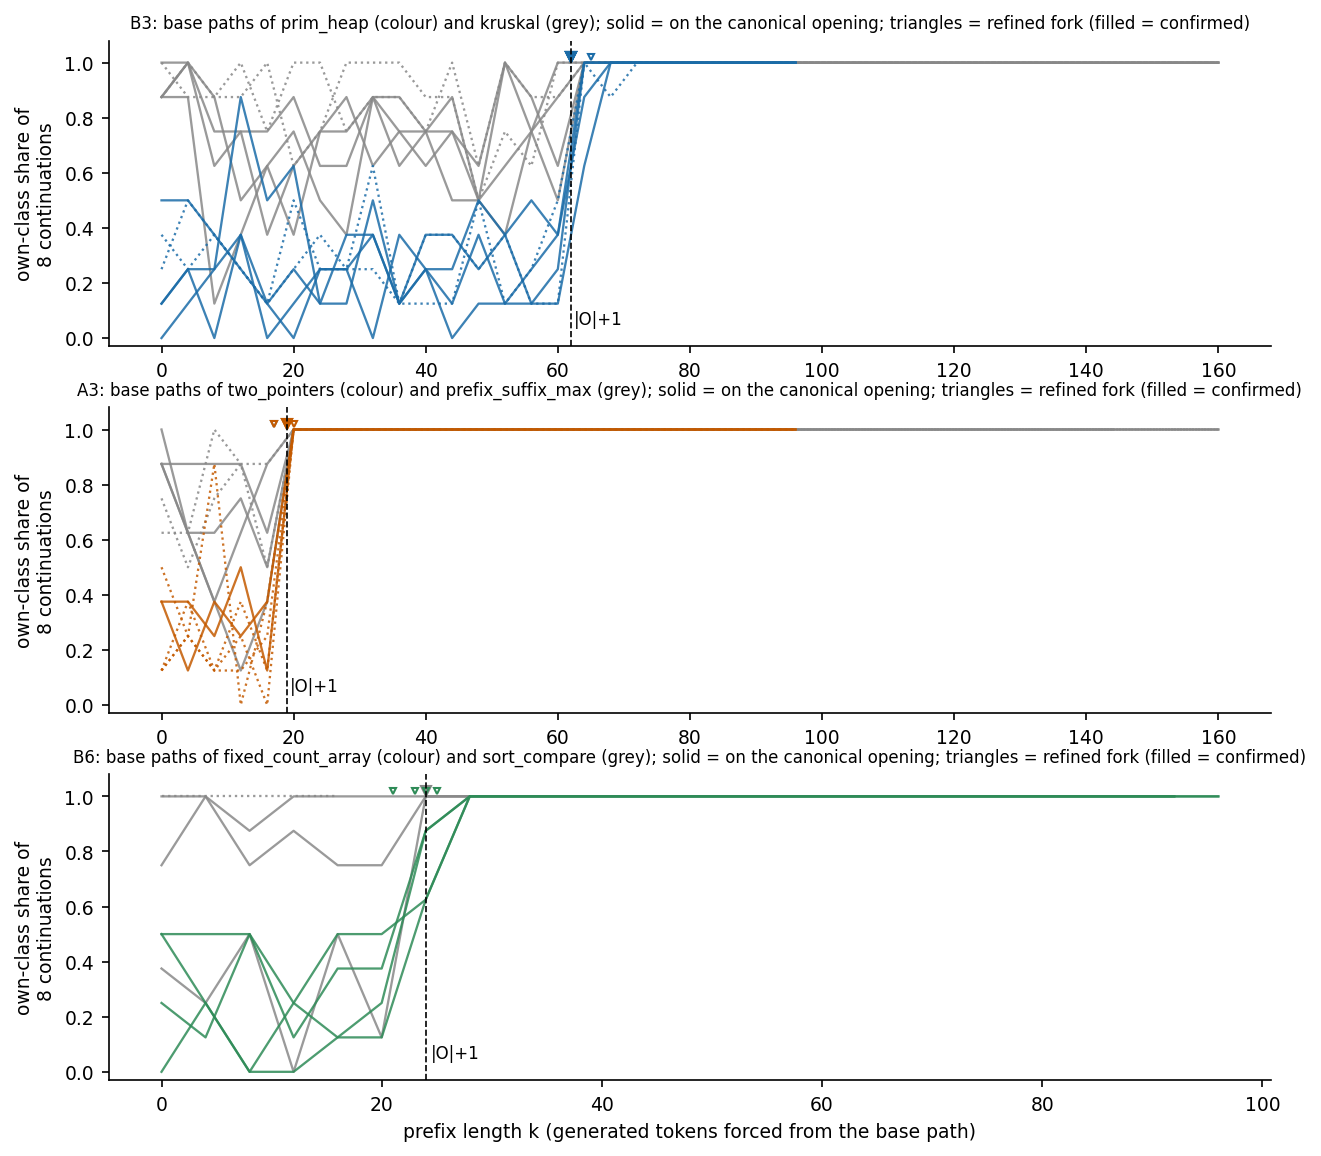

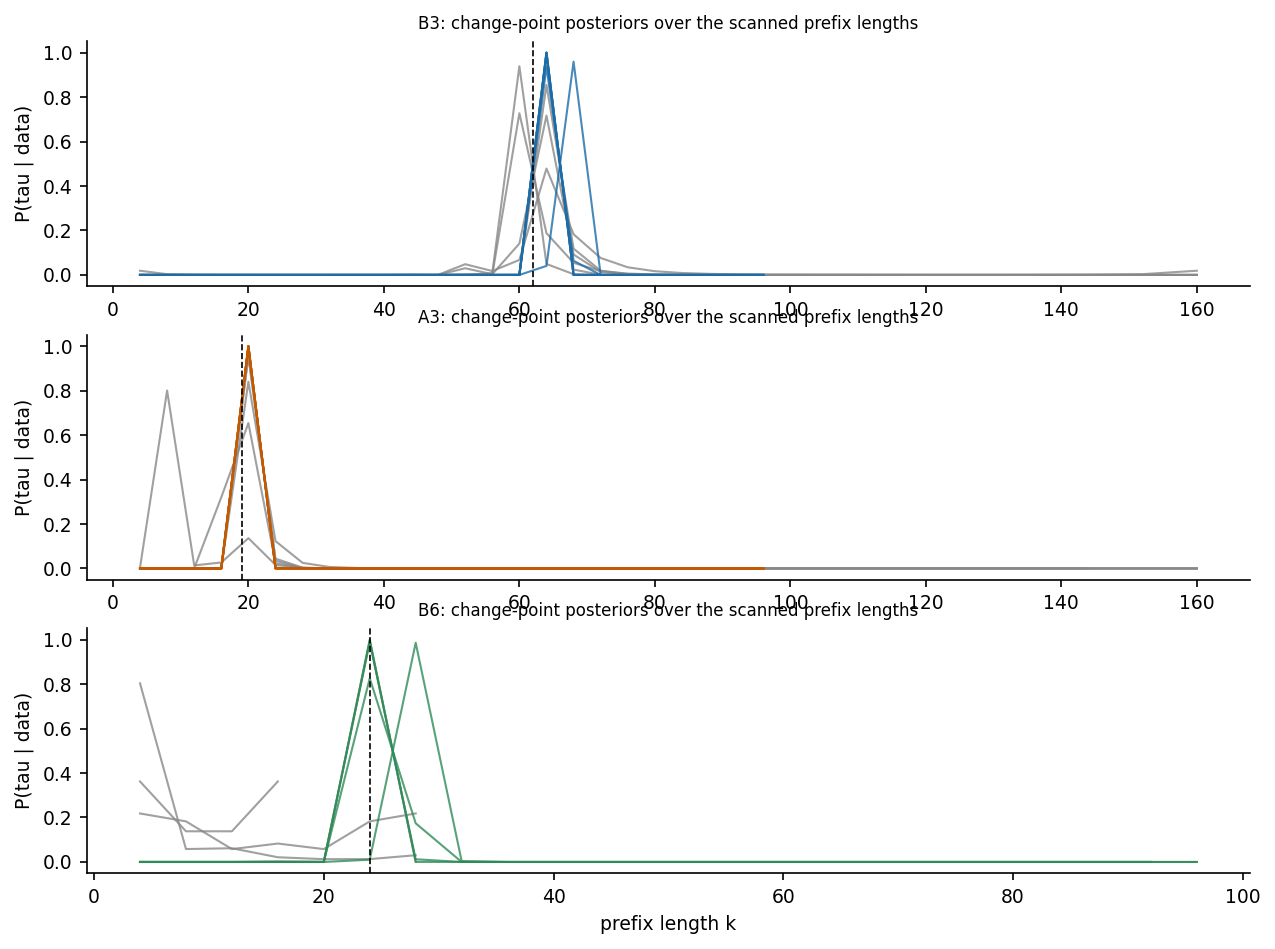

ok f1_outcome_curves


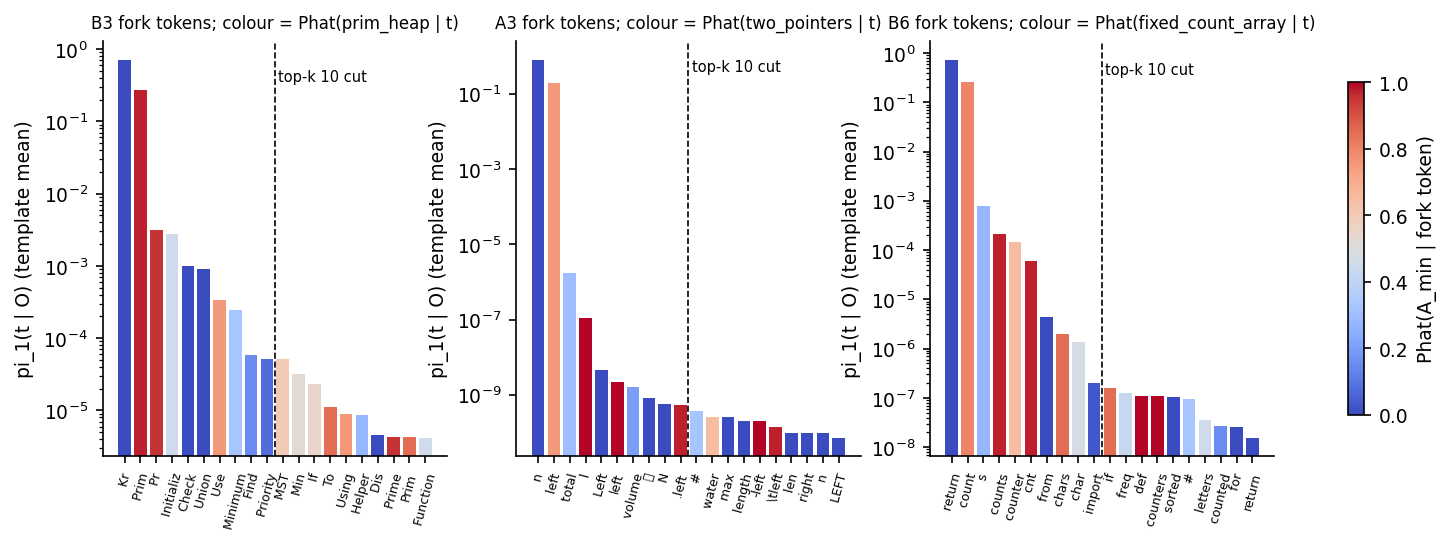

ok f2_fork_tokens


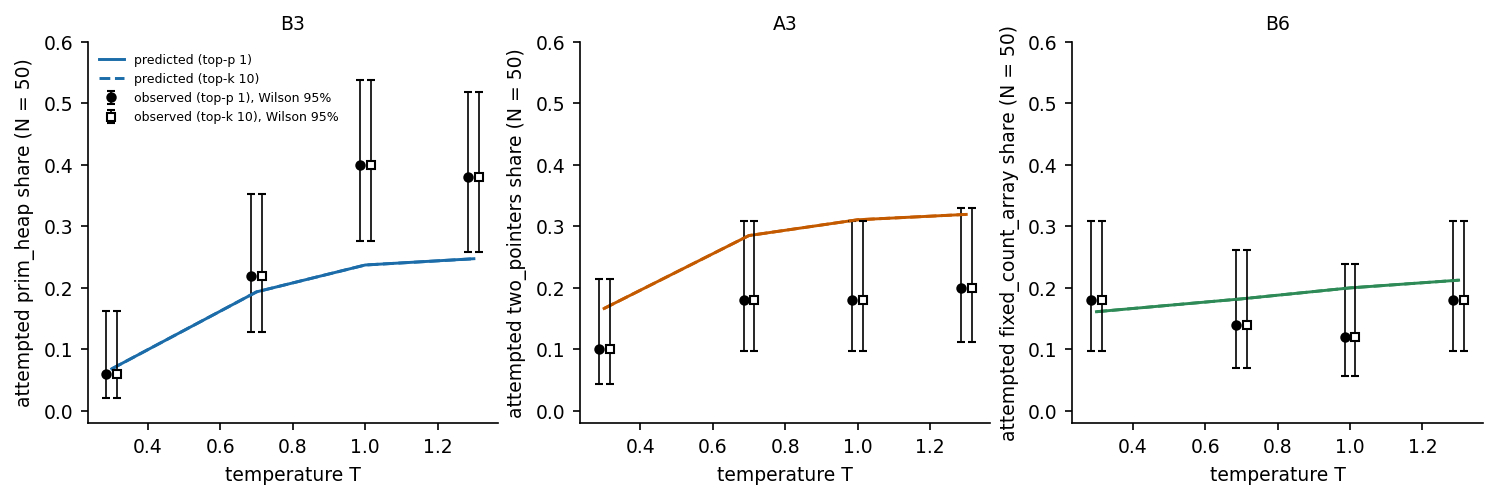

ok f3_pred_vs_obs


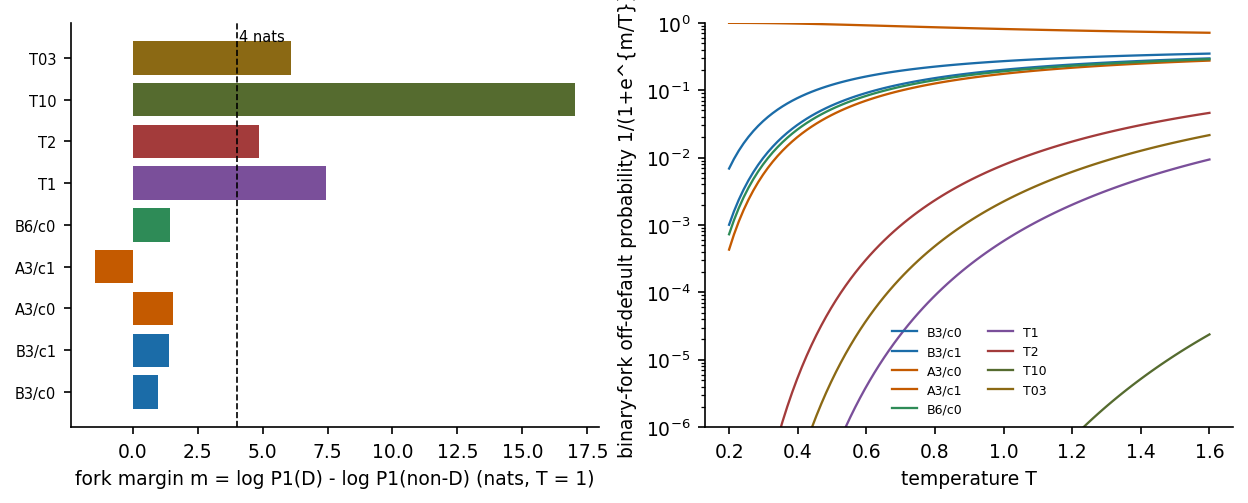

ok f4_margins


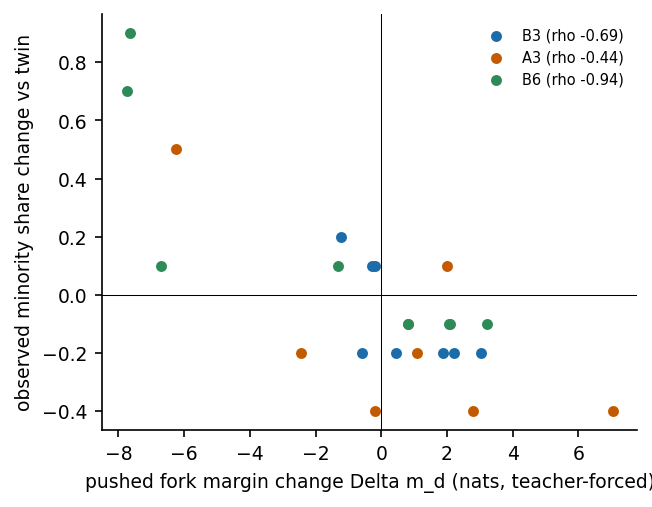

ok f5_s4a


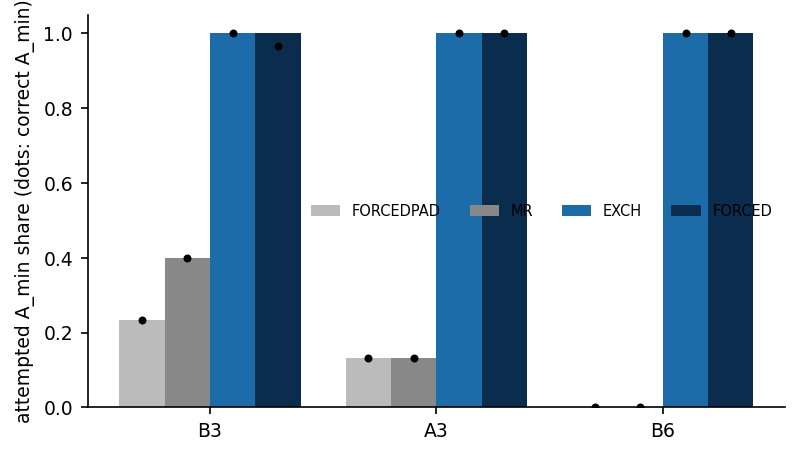

ok f6_s4b


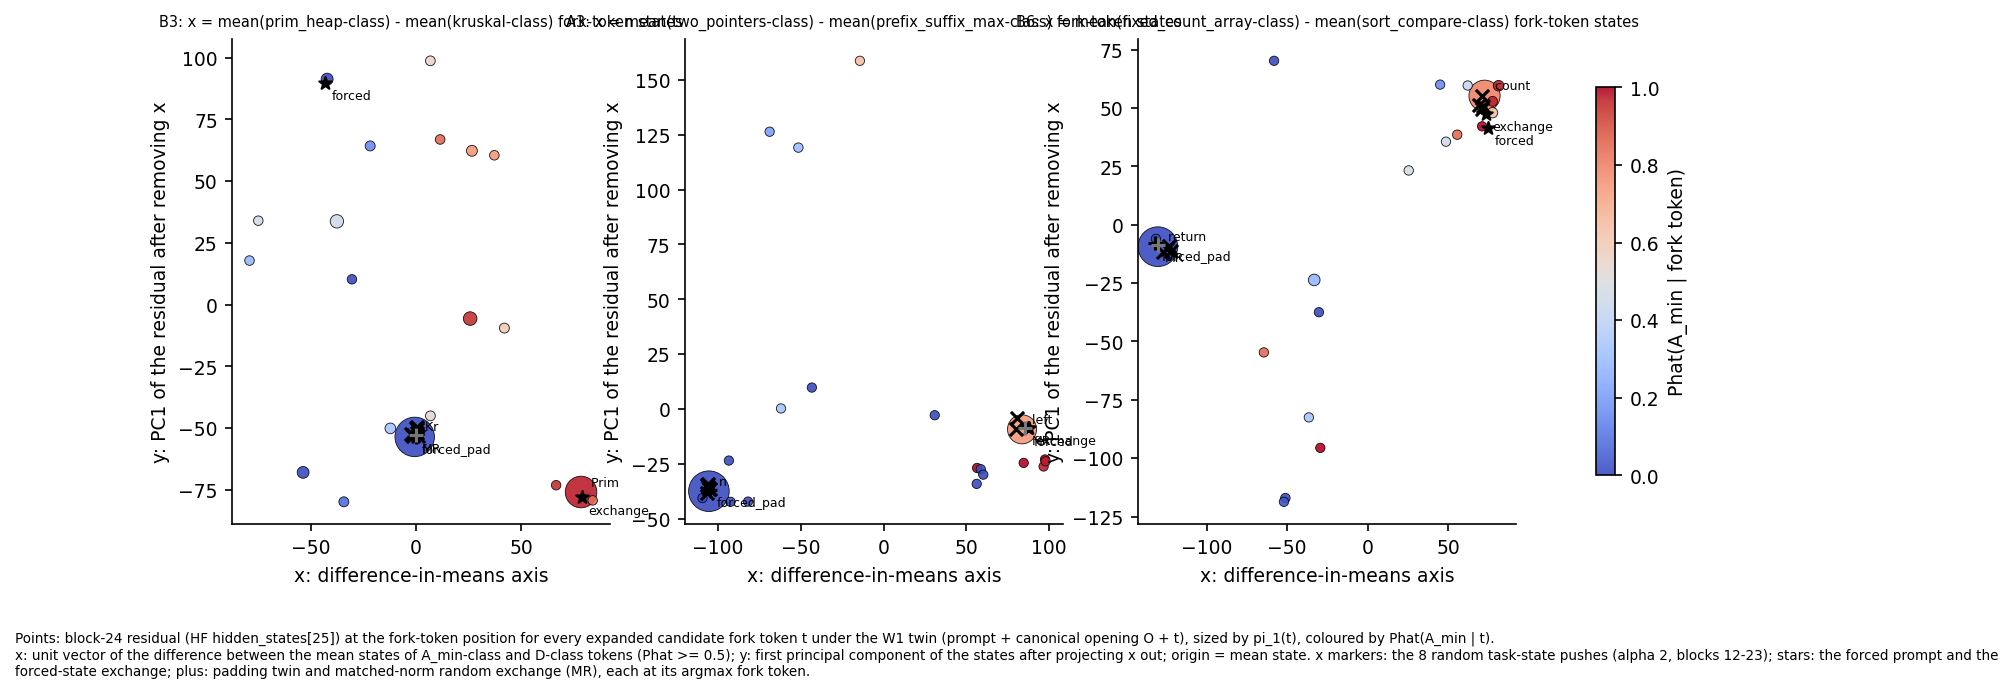

ok f7_geometry


In [29]:
# ---- src/figures7.py main()
import warnings  # notebook: a few fork-token labels in F2 are CJK characters that the default font lacks
warnings.filterwarnings("ignore", message=r"Glyph \d+ .* missing from font")
for f in (f1_outcome_curves, f2_fork_tokens, f3_pred_vs_obs, f4_margins, f5_s4a, f6_s4b, f7_geometry):
    try:
        f()
        print("ok", f.__name__)
    except Exception as e:  # noqa: BLE001 - one failing figure must not stop the others; reported
        print("FAILED", f.__name__, type(e).__name__, e)

In [30]:
# ---- notebook: F7 in numbers. The same x axis as f7_geometry(), rescaled so that 0 = the state of the most probable
# default-class fork token and 1 = that of the most probable minority-class token; "nearest" = the closest candidate
# fork-token state in the full 4096-d residual space
for u, z in GEOMETRY.items():
    cl = R[u]["clusters"][sorted(R[u]["clusters"])[0]]
    C, A, D = R[u]["cats"], R[u]["A_min"], R[u]["D"]
    X, toks = z["X"].astype(np.float64), [int(t) for t in z["toks"]]
    ph = np.array([np.array(cl["counts"][str(t)], float)[C.index(A)] / max(1, sum(cl["counts"][str(t)])) for t in toks])
    pd_ = np.array([np.array(cl["counts"][str(t)], float)[C.index(D)] / max(1, sum(cl["counts"][str(t)])) for t in toks])
    pi = np.array([cl["pi1_avg"][str(t)] for t in toks])
    isA, isD = ph >= 0.5, pd_ >= 0.5
    mu = X.mean(0)
    ax_x = X[isA].mean(0) - X[isD].mean(0)
    ax_x /= np.linalg.norm(ax_x)
    xs = (X - mu) @ ax_x
    iD = max(np.flatnonzero(isD), key=lambda i: pi[i])
    iA = max(np.flatnonzero(isA), key=lambda i: pi[i])
    txt = lambda i: repr(cl["tok_text"][str(toks[i])])
    print(f"{u}: x = 0 at {txt(iD)} ({D}), x = 1 at {txt(iA)} ({A})")
    push = []
    for name, e in zip(z["extra_names"], z["extra"].astype(np.float64)):
        kind, tstar = str(name).split("|", 1)
        x = (float((e - mu) @ ax_x) - xs[iD]) / (xs[iA] - xs[iD])
        d = np.linalg.norm(X - e, axis=1)
        j = int(np.argmin(d))
        if kind.startswith("push"):
            push.append((x, txt(j)))
            continue
        print(f"  {kind:10s} argmax {tstar!r:9s} x {x:5.2f}   nearest {txt(j):9s} (distance {d[j]:3.0f}; "
              f"to {txt(iD)} {d[iD]:3.0f}, to {txt(iA)} {d[iA]:3.0f})")
    print(f"  8 pushes   x {min(p[0] for p in push):.2f} to {max(p[0] for p in push):.2f}, nearest "
          f"{dict(Counter(p[1] for p in push))}")

B3: x = 0 at ' Kr' (kruskal), x = 1 at ' Prim' (prim_heap)
  forced     argmax ' Check'  x -0.54   nearest ' Check'  (distance  38; to ' Kr' 248, to ' Prim' 248)
  forced_pad argmax ' Kr'     x  0.01   nearest ' Kr'     (distance   7; to ' Kr'   7, to ' Prim' 193)
  exchange   argmax ' Prim'   x  1.01   nearest ' Prim'   (distance  24; to ' Kr' 195, to ' Prim'  24)
  MR         argmax ' Kr'     x  0.01   nearest ' Kr'     (distance  13; to ' Kr'  13, to ' Prim' 191)
  8 pushes   x -0.02 to 0.02, nearest {"' Kr'": 8}
A3: x = 0 at ' n' (prefix_suffix_max), x = 1 at ' left' (two_pointers)
  forced     argmax ' left'   x  1.02   nearest ' left'   (distance  74; to ' n' 238, to ' left'  74)
  forced_pad argmax ' n'      x  0.00   nearest ' n'      (distance   9; to ' n'   9, to ' left' 234)
  exchange   argmax ' left'   x  1.02   nearest ' left'   (distance  34; to ' n' 237, to ' left'  34)
  MR         argmax ' left'   x  1.01   nearest ' left'   (distance  16; to ' n' 236, to ' left'  16)

## 8. Results: the demo against the committed run

Each recomputed number sits next to the committed value from the artifact's `results/` files (`data["committed"]`). The
table covers:

- the fork scan;
- Test 1's entropy;
- Test 2's MAE, drops and McNemar tests;
- Test 3's margins;
- S4(a) and S4(b);
- the verdict;
- the ideas-vs-phrasings counts.

Bootstrap intervals and permutation p-values match only at the committed replicate counts, so the table compares them
only when the config is at those values.

In [31]:
# ---- notebook: every recomputed number next to the committed one
CMT = data["committed"]
CHECKS: list[tuple[str, Any, Any, bool]] = []


def check(name: str, mine: Any, committed: Any, tol: float = 1e-9) -> None:
    if isinstance(mine, (int, float, np.integer, np.floating)) and not isinstance(mine, bool) and committed is not None:
        ok = abs(float(mine) - float(committed)) <= tol * max(1.0, abs(float(committed)))
    else:
        ok = mine == committed
    CHECKS.append((name, mine, committed, ok))


def _fmt(x: Any) -> str:
    if isinstance(x, bool) or x is None:
        return str(x)
    if isinstance(x, (float, np.floating)):
        return f"{x:.4g}"
    if isinstance(x, (list, tuple)) and len(x) <= 4 and all(isinstance(e, (int, float)) for e in x):
        return ":".join(_fmt(e) for e in x)
    if isinstance(x, (list, tuple, dict)):
        return f"[{len(x)} items]"
    return str(x)


for u in MIXED:
    a, c = FORKS[u], FORKS_COMMITTED[u]
    check(f"{u} fork scan: opening length |O|", a["opening"]["len_O"], c["opening"]["len_O"])
    check(f"{u} fork scan: opening clusters", [x["O"] for x in a["opening"]["clusters"]], [x["O"] for x in c["opening"]["clusters"]])
    check(f"{u} fork scan: base paths", [b["bid"] for b in a["base_paths"]], [b["bid"] for b in c["base_paths"]])
    check(f"{u} fork scan: refined fork f per base path", {b: x.get("f") for b, x in a["per_base_path"].items()},
          {b: x.get("f") for b, x in c["per_base_path"].items()})
    check(f"{u} fork scan: confirmed / on O / at |O|+1", (a["n_confirmed"], a["n_confirmed_on_O"], a["n_at_O_plus_1"]),
          (c["n_confirmed"], c["n_confirmed_on_O"], c["n_at_O_plus_1"]))
    check(f"{u} fork scan: calibration Fisher p", a["calibration"]["fisher_p"], c["calibration"]["fisher_p"])
    check(f"{u} fork scan: mode", a["mode"], c["mode"])
    if N_PERM_FORK == 500:
        check(f"{u} fork scan: permutation p per base path", {b: x["perm"]["p_perm"] for b, x in a["per_base_path"].items()},
              {b: x["perm"]["p_perm"] for b, x in c["per_base_path"].items()})
for u in MIXED:
    check(f"{u} Test 1: H(A | fork class), bits", t1["per_unit"][u]["H_bits"], CMT["test1"]["per_unit"][u]["H_bits"])
    if N_BOOT_H == 1000:
        check(f"{u} Test 1: bootstrap 95% CI", [round(x, 12) for x in t1["per_unit"][u]["H_ci95"]],
              [round(x, 12) for x in CMT["test1"]["per_unit"][u]["H_ci95"]])
for u in MIXED:
    a, c = t2["per_unit"][u], CMT["test2"]["per_unit"][u]
    check(f"{u} Test 2: MAE over the 8 cells", a["MAE"], c["MAE"])
    check(f"{u} Test 2: observed drop T 1.0 -> 0.3", a["delta_obs_10_03"], c["delta_obs_10_03"])
    check(f"{u} Test 2: McNemar 1.0-only : 0.3-only", (a["mcnemar_b_10only"], a["mcnemar_c_03only"]),
          (c["mcnemar_b_10only"], c["mcnemar_c_03only"]))
    check(f"{u} Test 2: exact one-sided McNemar p", a["mcnemar_p_one_sided"], c["mcnemar_p_one_sided"])
    check(f"{u} Test 2: |obs - pred| change T 1.0 -> 1.3", a["abs_dev_10_13"], c["abs_dev_10_13"])
    check(f"{u} Test 2: replay accuracy, 8 cells", [x["replay_acc"] for x in a["cells"].values()],
          [x["replay_acc"] for x in c["cells"].values()])
    check(f"{u} Test 2: pass", a["pass"], c["pass"])
    if N_BOOT_DELTA == 2000:
        check(f"{u} Test 2: slot-bootstrap 95% CI of the drop", a["delta_obs_ci95"], c["delta_obs_ci95"])
check("Test 2: pooled B3 + A3 McNemar p", t2["pooled_B3_A3"]["p"], CMT["test2"]["pooled_B3_A3"]["p"])
for t in COLLAPSED:
    a, c = t3["per_task"][t], CMT["test3"]["per_task"][t]
    check(f"{t} Test 3: fork margin, nats", a["margin_nats"], c["margin_nats"])
    check(f"{t} Test 3: T 1.3 check, off-default programs", a["check_T13"]["n_off_any"], c["check_T13"]["n_off_any"])
for u in MIXED:
    a, c = S4B_RES[u], CMT["s4b"][u]
    check(f"{u} S4(b): attempted A_min, FORCED/PAD/EXCH/MR",
          tuple(a["arms"][x]["attempted_a_min"] for x in ("FORCED", "FORCEDPAD", "EXCH", "MR")),
          tuple(c["arms"][x]["attempted_a_min"] for x in ("FORCED", "FORCEDPAD", "EXCH", "MR")))
    check(f"{u} S4(b): exchange vs pad McNemar p", a["exchange_vs_pad"]["p_one_sided"], c["exchange_vs_pad"]["p_one_sided"])
    check(f"{u} S4(b): d margin exchange (teacher-forced)", a["d_margin_exchange"], c["d_margin_exchange"], 1e-6)
    check(f"{u} S4(b): d margin MR (teacher-forced)", a["d_margin_MR"], c["d_margin_MR"], 1e-6)
    check(f"{u} S4(a): Spearman rho", S4A_RES[u]["spearman_dmargin_dshare"], CMT["s4a"][u]["spearman_dmargin_dshare"])
    if N_PERM_S4A is None:
        check(f"{u} S4(a): lower-tail permutation p", S4A_RES[u]["perm_p_one_sided_negative"],
              CMT["s4a"][u]["perm_p_one_sided_negative"])
for u in MIXED:
    a, c = T1AC[u], CMT["table_1ac"][u]
    D = UNITS[u]["default"]
    check(f"{u} 1a-c: {D} phrasing clusters (theta 0.9), T 0.3..1.3",
          tuple(a["cells"][f"T{T}_p1"]["phrasing_clusters"][D]["theta0.9"]["single"] for T in TEMPS),
          tuple(c["cells"][f"T{T}_p1"]["phrasing_clusters"][D]["theta0.9"]["single"] for T in TEMPS))
    check(f"{u} 1a-c: slots whose idea changes across T", a["per_slot_idea_changes"]["p1"]["slots_with_idea_change_across_T"],
          c["per_slot_idea_changes"]["p1"]["slots_with_idea_change_across_T"])
    if HILL_REPS == 300:
        check(f"{u} 1a-c: correct-only Hill-1 at T 1.0 (rarefied 25)", a["cells"]["T1.0_p1"]["hill1_correct_rarefied25"],
              c["cells"]["T1.0_p1"]["hill1_correct_rarefied25"])
check("verdict", v["verdict"], CMT["verdict"]["verdict"])
check("verdict: test passes", v["passes"], CMT["verdict"]["passes"])

w = max(len(c[0]) for c in CHECKS)
print(f"  {'quantity':{w}s}  {'this notebook':>20s}  {'committed':>20s}")
for name, mine, cm, ok in CHECKS:
    print(f"{'✓' if ok else '✗'} {name:{w}s}  {_fmt(mine):>20s}  {_fmt(cm):>20s}")
print(f"\n{sum(c[3] for c in CHECKS)} / {len(CHECKS)} recomputed numbers equal the committed ones "
      f"(config: N_BOOT_H {N_BOOT_H}, N_BOOT_DELTA {N_BOOT_DELTA}, N_PERM_FORK {N_PERM_FORK}, HILL_REPS {HILL_REPS}, "
      f"N_PERM_S4A {N_PERM_S4A})")

  quantity                                                                     this notebook             committed
✓ B3 fork scan: opening length |O|                                                        61                    61
✓ B3 fork scan: opening clusters                                                   [2 items]             [2 items]
✓ B3 fork scan: base paths                                                        [12 items]            [12 items]
✓ B3 fork scan: refined fork f per base path                                      [12 items]            [12 items]
✓ B3 fork scan: confirmed / on O / at |O|+1                                            5:3:3                 5:3:3
✓ B3 fork scan: calibration Fisher p                                                  0.5752                0.5752
✓ B3 fork scan: mode                                                               ONE-TOKEN             ONE-TOKEN
✓ B3 fork scan: permutation p per base path                                     

### Is temperature the creativity knob? One figure

- **(a) Temperature, predicted vs observed.** The committed predictions (lines) against the same-seed sweep (points,
  Wilson 95%), top-p 1. Lowering T collapses B3 onto Kruskal, as predicted. Raising T from 1.0 to 1.3 adds nothing.
- **(b) How far temperature can reach.** For a binary fork with margin m, the off-default probability is
  1 / (1 + e^(m/T)). The three mixed forks sit about 1–1.5 nats apart. The collapsed tasks sit 4.85–17 nats apart, so
  no reasonable T reaches their alternative.
- **(c) What does move the choice.** The prediction function on the real teacher-forced logits of the S4(b) arms (A3,
  B6), against T. The dotted line is the padding twin, the solid line the forced-state exchange. Markers are the
  observed shares at T 1 (30 slots each), nudged apart in x so both units show.
  - On B6, temperature cannot make the padding twin write the count array (< 0.03 up to T 2).
  - Exchanging the task states does it on 30/30 seeds.
  - The exchange prediction (about 0.4 for A3, 0.78 for B6) reuses the unexchanged P̂(A | t). It captures the flipped
    fork token but not what the exchanged states do after it.

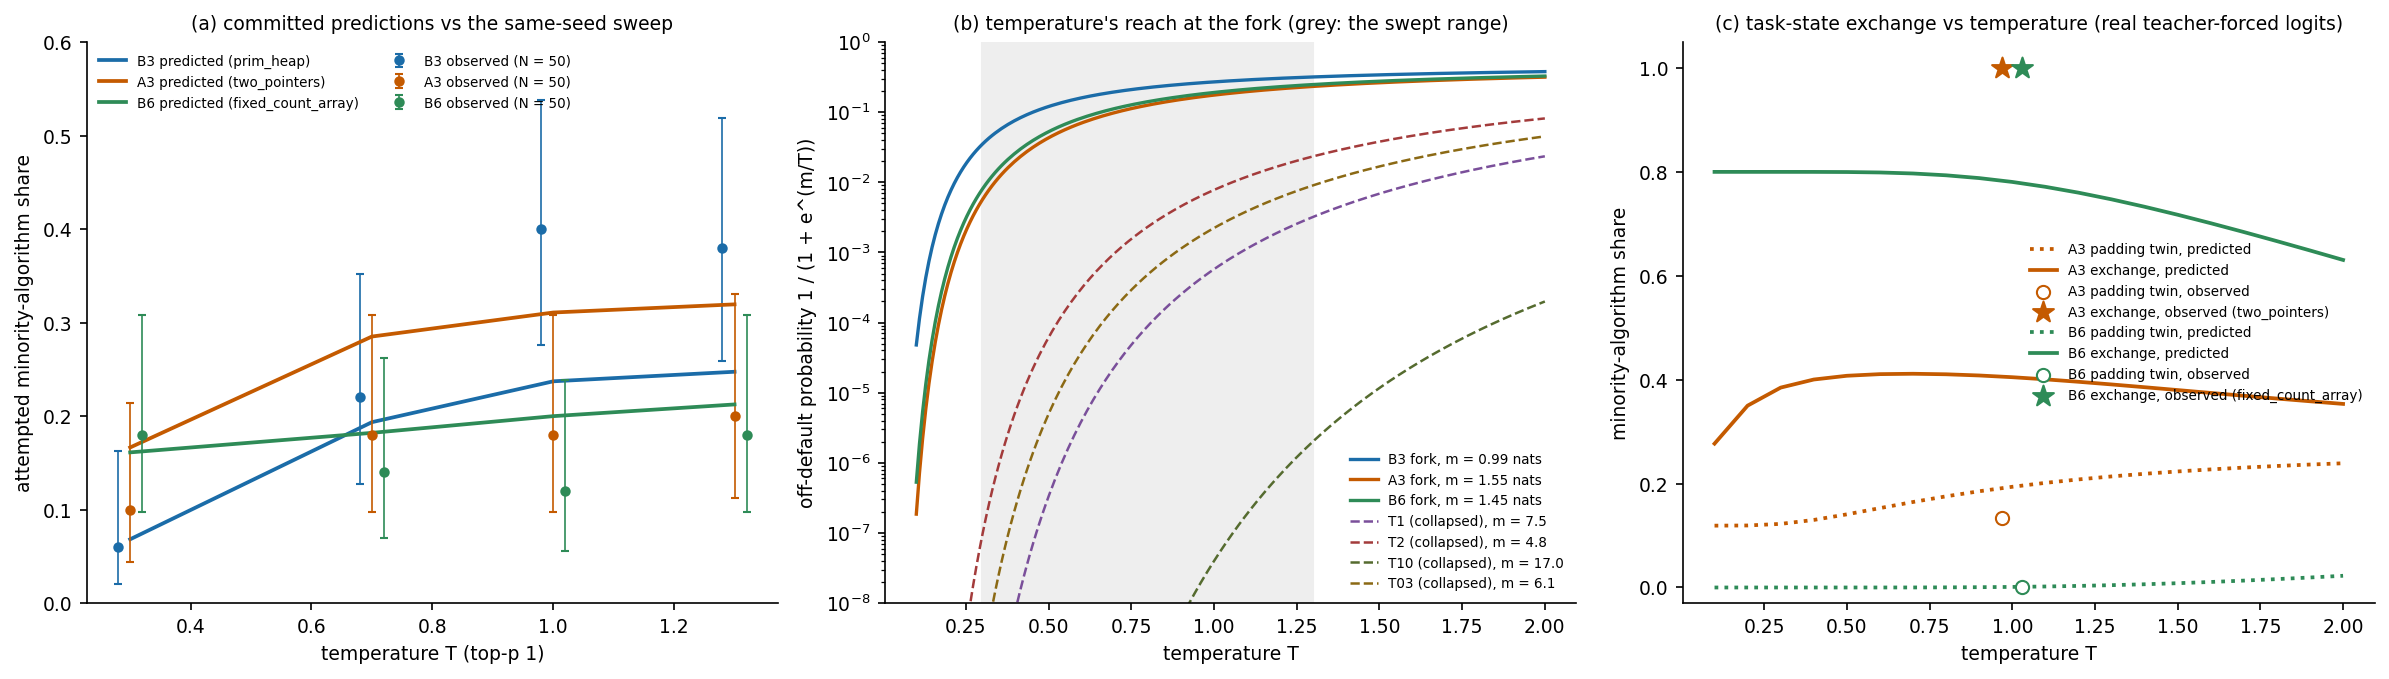

In [32]:
# ---- notebook: summary figure
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ax = axes[0]
for j, u in enumerate(MIXED):
    U, cells = pv["units"][u], t2["per_unit"][u]["cells"]
    pred = [U["cells"][f"T{T}_p1"]["a_min"] for T in TEMPS]
    obs = np.array([cells[f"T{T}_p1"]["a_min"] for T in TEMPS])
    lo = np.array([cells[f"T{T}_p1"]["a_min_ci"][0] for T in TEMPS])
    hi = np.array([cells[f"T{T}_p1"]["a_min_ci"][1] for T in TEMPS])
    ax.plot(TEMPS, pred, "-", color=COL[u], lw=1.8, label=f"{u} predicted ({U['A_min']})")
    ax.errorbar(np.array(TEMPS) + 0.02 * (j - 1), obs, yerr=[obs - lo, hi - obs], fmt="o", color=COL[u], ms=4,
                capsize=2, lw=0.8, label=f"{u} observed (N = 50)")
ax.set_xlabel("temperature T (top-p 1)")
ax.set_ylabel("attempted minority-algorithm share")
ax.set_title("(a) committed predictions vs the same-seed sweep", fontsize=9)
ax.set_ylim(0, 0.6)
ax.legend(fontsize=6.5, frameon=False, ncol=2, loc="upper left")

ax = axes[1]
Ts = np.linspace(0.1, 2.0, 200)
for u in MIXED:
    m = pv["units"][u]["margins"]["c0"]["mean"]
    ax.plot(Ts, [binary_closed_form(m, T) for T in Ts], color=COL[u], lw=1.6, label=f"{u} fork, m = {m:.2f} nats")
for t in COLLAPSED:
    m = pv["collapsed"][t]["margin_nats"]
    ax.plot(Ts, [binary_closed_form(m, T) for T in Ts], "--", color=COL[t], lw=1.2, label=f"{t} (collapsed), m = {m:.1f}")
ax.axvspan(0.3, 1.3, color="#eeeeee", zorder=0)
ax.set_yscale("log")
ax.set_ylim(1e-8, 1)
ax.set_xlabel("temperature T")
ax.set_ylabel("off-default probability 1 / (1 + e^(m/T))")
ax.set_title("(b) temperature's reach at the fork (grey: the swept range)", fontsize=9)
ax.legend(fontsize=6.5, frameon=False, loc="lower right")

ax = axes[2]
for j, u in enumerate(S4_CURVES):
    A, x_obs = R[u]["A_min"], 1.0 + 0.03 * (2 * j - 1)
    ax.plot(T_CURVE, S4_CURVES[u]["forced_pad"]["a_min"], ":", color=COL[u], lw=1.8, label=f"{u} padding twin, predicted")
    ax.plot(T_CURVE, S4_CURVES[u]["exchange"]["a_min"], "-", color=COL[u], lw=1.8, label=f"{u} exchange, predicted")
    ax.scatter([x_obs], [S4B_RES[u]["arms"]["FORCEDPAD"]["attempted_a_min"]], marker="o", facecolor="white",
               edgecolor=COL[u], s=40, zorder=3, label=f"{u} padding twin, observed")
    ax.scatter([x_obs], [S4B_RES[u]["arms"]["EXCH"]["attempted_a_min"]], marker="*", color=COL[u], s=110, zorder=3,
               label=f"{u} exchange, observed ({A})")
ax.set_xlabel("temperature T")
ax.set_ylabel("minority-algorithm share")
ax.set_title("(c) task-state exchange vs temperature (real teacher-forced logits)", fontsize=9)
ax.set_ylim(-0.03, 1.05)
ax.legend(fontsize=6.5, frameon=False, loc="center right")
fig.tight_layout()
fig.savefig(FIG_DIR / "summary_temperature_knob.png", dpi=150, bbox_inches="tight")
plt.show()

### What a temperature flip looks like

The cell finds a B3 seed position (same template, same uniform stream) whose program is Kruskal at T 0.3 and Prim at
T 1.0. It prints the start of both programs. They share the canonical opening up to `    # `, and the next word decides
the algorithm.

In [33]:
# ---- notebook: one B3 seed position whose algorithm changes with temperature (top-p 1)
for ex in data["examples"]:
    by = {p["cell"]: p for p in ex["programs"] if p["unit"] == "B3"}
    if by["T0.3_p1"]["label"] == "kruskal" and by["T1.0_p1"]["label"] == "prim_heap":
        break
print(f"B3, template {ex['template']}, slot {ex['slot']}: the label in each cell")
print("  " + ", ".join(f"{c} {by[c]['label']}" for c in [f"T{T}_{s}" for s in SAMPLERS for T in TEMPS]))
for cell in ("T0.3_p1", "T1.0_p1"):
    p = by[cell]
    print(f"\n--- {cell}: {p['label']} (hidden tests: {'pass' if p['passed'] else 'fail'}) ---")
    print("\n".join((p["code"] or "").splitlines()[:11]))

B3, template W1, slot 21: the label in each cell
  T0.3_p1 kruskal, T0.7_p1 kruskal, T1.0_p1 prim_heap, T1.3_p1 prim_heap, T0.3_k10 kruskal, T0.7_k10 kruskal, T1.0_k10 prim_heap, T1.3_k10 prim_heap

--- T0.3_p1: kruskal (hidden tests: pass) ---
def solve(n, roads):
    import heapq

    # Build adjacency list
    graph = [[] for _ in range(n)]
    for u, v, w in roads:
        graph[u].append((v, w))
        graph[v].append((u, w))

    # Kruskal's algorithm using Union-Find
    parent = list(range(n))

--- T1.0_p1: prim_heap (hidden tests: pass) ---
def solve(n, roads):
    import heapq

    # Build adjacency list
    graph = [[] for _ in range(n)]
    for u, v, w in roads:
        graph[u].append((v, w))
        graph[v].append((u, w))

    # Prim's algorithm
    visited = [False] * n


## Notes

**What is reproduced here, and what is loaded.**

- **Runs here.** The fork scan's analysis, Test 1, the prediction function on the S4(b) logits, the per-seed replay on
  the S4(b) arms, the committed scoring (Tests 1–3, verdict, S4(a), S4(b), 1a–c) and all figures.
- **Loaded from COMMIT #2.** The 24 temperature-cell predictions, the per-slot sweep replay, the opening margins, and
  the S4(a) / B3 S4(b) teacher-forced numbers. They need teacher-forced logits that were deleted after the round; the
  restore command is in the experiment's README.
- **Loaded from the GPU stages.** All generated programs and continuations, with their labels.

**Full run.** On a CUDA GPU with ≥ 20 GB:

`uv pip install -r pyproject.toml; python src/download_models.py; python method.py all`

The committed run took about 0.75 GPU-hours on an RTX 4090 plus USD 0.022 of OpenRouter judge calls.

**Config.** The config cell holds the committed values (`N_BOOT_H = 1000`, `N_BOOT_DELTA = 2000`, `N_PERM_FORK = 500`,
`N_U4_RUNS = 200`, `HILL_REPS = 300`, `N_PERM_S4A = None`), so the notebook reproduces every interval and p-value of
the committed scoring. The exact S4(a) enumeration takes about two of the notebook's three minutes. `N_PERM_S4A = 5000`
makes it take seconds, with approximate S4(a) p-values.